# PG-LSTM: прогноз уровня Амура у Хабаровска на 14 суток

**Задача.** По данным на день прогноза предсказать уровень воды на гидропосту Хабаровск на 1…14 суток вперёд.

**Модель — PG-LSTM** (Physics-Guided LSTM, физически-информированная LSTM). Это рекуррентная нейросеть, которая учится на истории наблюдений, а физика реки входит в неё двумя путями:

1. **физическая модель** — уравнение маршрутизации паводковой волны (Маскингам / Калинин–Милюков) — сама строит прогноз по постам выше по течению, а сеть учится его поправлять;
2. **физические штрафы в функции потерь**: сеть наказывается, если её прогноз нарушает уравнение маршрутизации (уровень в Хабаровске должен откликаться на подъёмы и спады выше по течению с правильным запаздыванием и сглаживанием) или предельную скорость подъёма и спада уровня, которая наблюдалась в истории для каждого месяца.

**Прогноз честный.** Модель видит только данные до дня прогноза включительно: ни фактической погоды, ни уровней из будущего. Заглянуть вперёд ей помогают посты выше по течению, потому что волна идёт от них до Хабаровска 2–9 суток.

**Содержание**
1. Настройка
2. Данные: источники, очистка, дополнение
3. Физика реки: время добегания, уравнение маршрутизации, предельная скорость
4. Модель PG-LSTM
5. Обучение и выбор веса физики λ
6. Тестирование на 2019–2026 годах
7. Сохранение модели и прогноз
8. Подключение к проекту river_monitor
9. Выводы

### Итог в цифрах

Тест на 2019–2026 годах: эти данные модель при обучении не видела.

| Заблаговременность | 1 сут | 3 сут | 7 сут | 14 сут |
|---|---|---|---|---|
| **MAE PG-LSTM, см** | **4,0** | **11,1** | **24,2** | **41,9** |
| MAE обычной LSTM, см | 6,1 | 16,3 | 29,5 | 44,3 |
| MAE физической модели, см | 4,1 | 11,7 | 28,3 | 57,1 |
| MAE инерционного прогноза («как сегодня»), см | 7,9 | 21,7 | 43,6 | 70,9 |
| S/σΔ PG-LSTM (≤ 0,8 — удовлетворительно) | 0,77 | 0,69 | 0,63 | 0,61 |

* PG-LSTM — лучшая из пяти моделей на всех горизонтах 1–14 суток.
* По критерию Росгидромета это удовлетворительная методика на всех горизонтах.
* Её прогнозы физически согласованнее, чем у обычной LSTM: невязка уравнения маршрутизации 0,6 против 3,3 см/сут, превышений предельной скорости 0,17% прогнозов против 0,26%.

## 1. Настройка

**На компьютере:** откройте блокнот из папки `amur_pg_lstm` и выполните все ячейки по порядку (Run All). Нужны пакеты `numpy pandas matplotlib requests torch`.

**В Google Colab:** загрузите папку `amur_pg_lstm` на Google Диск и раскомментируйте две строки в первой ячейке. PyTorch в Colab уже установлен.

Обучение 25 сетей занимает около 15 минут на Mac M4. Если нужно быстрее, поставьте `FAST = True`: будет 3 сети на вариант и только λ = 1.

In [1]:
# --- Google Colab: раскомментируйте ---
# from google.colab import drive; drive.mount('/content/drive')
# import os; os.chdir('/content/drive/MyDrive/amur_pg_lstm')

import copy, importlib, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import requests
import torch
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.width', 160)

BASE = Path('.')
RAW, FIG, MODEL_DIR = BASE / 'data' / 'raw', BASE / 'figures', BASE / 'model'
for p in (RAW, FIG, MODEL_DIR):
    p.mkdir(parents=True, exist_ok=True)

FAST = False                                   # True — быстрый режим (меньше сетей)
TRAIN_END, VAL_END = '2015-12-31', '2018-12-31'  # обучение 2002–2015, валидация 2016–2018, тест 2019–2026
print('torch', torch.__version__)

torch 2.14.1


In [2]:
# Оформление графиков
INK, INK2, MUTED, GRID, AXIS, SURF = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
COL = {'PG-LSTM': '#2a78d6', 'LSTM': '#eb6834', 'Физическая модель': '#1baf7a', 'Инерционный': '#eda100',
       'LSTM + физ. вход': '#e87ba4'}
GAUGE_RU = {'khabarovsk': 'Хабаровск', 'blagoveshchensk': 'Благовещенск', 'poyarkovo': 'Поярково', 'leninskoe': 'Ленинское'}
GAUGE_COL = {'khabarovsk': INK, 'blagoveshchensk': '#2a78d6', 'poyarkovo': '#eb6834', 'leninskoe': '#1baf7a'}
# пороги для Хабаровска из river_monitor/config.py
THRESH = [(300, 'повышенная готовность', '#fab219'), (470, 'неблагоприятное явление', '#ec835a'),
          (550, 'опасное явление', '#d03b3b')]
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'text.color': INK, 'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 1.6,
    'legend.frameon': False, 'font.size': 10, 'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})


def show(fig, name):
    fig.savefig(FIG / name)
    plt.show()


def thresholds(ax, labels=True):
    """Пороги уровня справа от графика; подписи раздвигаются, если линии близко."""
    for v, name, c in THRESH:
        ax.axhline(v, color=c, lw=1, zorder=1)
    if not labels:
        return
    lo, hi = ax.get_ylim()
    last = -1.0
    for v, name, c in THRESH:
        y = max((v - lo) / (hi - lo), last + 0.1)
        if y <= 1:
            ax.text(1.005, y, f'{v} — {name}', transform=ax.transAxes, color=INK2, fontsize=8, va='center')
        last = y

### Модуль `pg_lstm.py`

Всё, что нужно обученной модели вне блокнота, лежит в одном модуле: очистка уровней, погода ERA5, модель снега, признаки, сеть и функция прогноза. Ячейка ниже **создаёт файл** `pg_lstm.py` рядом с блокнотом. Этот же файл потом копируется в проект river_monitor (раздел 8). Блокнот пользуется теми же функциями, поэтому код существует в одном экземпляре.

In [3]:
%%writefile pg_lstm.py
"""PG-LSTM — физически-информированная LSTM для прогноза уровня Амура у Хабаровска на 14 суток.

Файл создаётся блокнотом PG_LSTM_Хабаровск.ipynb (ячейка %%writefile) — правки вносите там.
Здесь всё, что нужно для работы обученной модели вне блокнота: очистка уровней, погода ERA5
по бассейну, модель снега, физическая модель маршрутизации волны, признаки, сама сеть и прогноз.
"""
import time

import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn

GAUGES = ['khabarovsk', 'blagoveshchensk', 'poyarkovo', 'leninskoe']
UPSTREAM = GAUGES[1:]

# Точки ERA5 (Open-Meteo) по частям бассейна: (широта, долгота)
ERA5_POINTS = {
    'khabarovsk': (48.48, 135.07), 'birobidzhan': (48.79, 132.92),             # местный приток
    'blagoveshchensk': (50.28, 127.54), 'zeya': (53.73, 127.27), 'bureya': (51.10, 132.00),  # Амур, Зея, Бурея
    'harbin': (45.75, 126.65), 'jiamusi': (46.80, 130.36), 'mudanjiang': (44.58, 129.60),    # Сунгари
    'dalnerechensk': (45.93, 133.73),                                           # Уссури
}
GROUPS = {'local': ['khabarovsk', 'birobidzhan'], 'amur': ['blagoveshchensk', 'zeya', 'bureya'],
          'sungari': ['harbin', 'jiamusi', 'mudanjiang'], 'ussuri': ['dalnerechensk']}
ERA5_VARS = 'temperature_2m_mean,precipitation_sum,rain_sum,snowfall_sum,et0_fao_evapotranspiration'

DDF, T_MELT = 3.0, 0.0           # коэффициент стаивания, мм/(°C·сут), и порог таяния, °C
WINDOW, HORIZON, SCALE = 60, 14, 50.0

# --- очистка уровней -------------------------------------------------------
VALID_RANGE = {'khabarovsk': (-350, 900), 'blagoveshchensk': (-200, 950),
               'poyarkovo': (-250, 950), 'leninskoe': (-150, 1100)}
# допустимое отклонение от медианы соседних наблюдений, см; шире в ледоход (апрель) и ледостав (ноябрь)
SPIKE_T = {
    'khabarovsk': {1: 40, 2: 40, 3: 60, 4: 200, 5: 40, 6: 40, 7: 40, 8: 40, 9: 40, 10: 40, 11: 120, 12: 80},
    'upstream': {1: 60, 2: 60, 3: 80, 4: 250, 5: 200, 6: 150, 7: 150, 8: 150, 9: 150, 10: 150, 11: 150, 12: 100},
}
EXPERT_BAD = {'khabarovsk': [('2023-03-21', '2023-04-10')]}   # сбой датчика: от −987 до +662 см за сутки


def find_bad(s, name):
    """Маска ошибочных значений ряда уровня (индекс — даты наблюдений)."""
    lo, hi = VALID_RANGE[name]
    thr = SPIKE_T['khabarovsk' if name == 'khabarovsk' else 'upstream']
    bad = (s < lo) | (s > hi)                                        # коды ошибок 1050/1056 и т. п.
    bad |= (s == 0) & (s.index.to_series().diff().dt.days >= 7)      # «0» — заглушка после пропуска
    for a, b in EXPERT_BAD.get(name, []):
        bad[a:b] = True
    for _ in range(50):                                              # одиночные выбросы, по одному за шаг
        x = s[~bad]
        dev = (x - x.rolling(5, center=True, min_periods=3).median()).abs()
        cand = dev[dev > x.index.month.map(thr).values]
        if cand.empty:
            break
        bad[cand.idxmax()] = True
    return bad


def clean_level(s, name, days):
    """Убирает ошибки, ставит ряд на сетку дней `days`, заполняет пропуски интерполяцией.
    Возвращает (уровень, флаг «значение восстановлено»)."""
    s = s.dropna().sort_index()
    s = s[~s.index.duplicated()]
    s = s[~find_bad(s, name)].reindex(days)
    filled = s.isna().astype(int)
    return s.interpolate('time', limit_direction='both').round(1), filled


# --- погода и снег ----------------------------------------------------------
def fetch_era5(name, start, end, retries=6):
    """Суточная погода ERA5 из архива Open-Meteo для точки бассейна."""
    lat, lon = ERA5_POINTS[name]
    for _ in range(retries):
        r = requests.get('https://archive-api.open-meteo.com/v1/archive', timeout=120, params=dict(
            latitude=lat, longitude=lon, start_date=str(start)[:10], end_date=str(end)[:10],
            daily=ERA5_VARS, timezone='Asia/Vladivostok'))
        if r.status_code == 429:          # лимит запросов в минуту — ждём
            time.sleep(65)
            continue
        r.raise_for_status()
        d = pd.DataFrame(r.json()['daily'])
        d.index = pd.to_datetime(d.pop('time'))
        return d
    raise RuntimeError('Open-Meteo не отвечает: ' + name)


def snow_model(temp, precip, rain, ddf=DDF, t_melt=T_MELT):
    """Модель снежного покрова по градусо-дням.
    Твёрдые осадки (precip − rain) копятся в запасе воды в снеге SWE, тает
    min(SWE, ddf·max(T − t_melt, 0)) мм/сут. Возвращает (таяние, SWE) в мм."""
    snow = np.clip(np.asarray(precip) - np.asarray(rain), 0, None)
    temp = np.asarray(temp)
    melt, swe, S = np.zeros(len(temp)), np.zeros(len(temp)), 0.0
    for i in range(len(temp)):
        S += snow[i]
        m = min(S, ddf * max(temp[i] - t_melt, 0.0))
        S -= m
        melt[i], swe[i] = m, S
    return melt, swe


def basin_weather(era5, days):
    """Средние по частям бассейна: температура, осадки, водоотдача (дождь + таяние), запас воды в снеге."""
    pts = {}
    for n, e in era5.items():
        e = e.sort_index()
        melt, swe = snow_model(e['temperature_2m_mean'], e['precipitation_sum'], e['rain_sum'])
        pts[n] = pd.DataFrame({'temp': e['temperature_2m_mean'], 'precip': e['precipitation_sum'],
                               'water_input': e['rain_sum'] + melt, 'swe': swe}, index=e.index).reindex(days)
    out = pd.DataFrame(index=days)
    for g, names in GROUPS.items():
        m = sum(pts[n] for n in names) / len(names)
        for v, nd in [('temp', 2), ('precip', 2), ('water_input', 2), ('swe', 1)]:
            out[f'{g}_{v}'] = m[v].round(nd)
    return out


def prepare_inputs(levels, end=None, era5=None):
    """Собирает таблицу для прогноза из сырых уровней 4 постов.
    levels: {'khabarovsk': pd.Series(уровень, индекс=даты), ...} — все 4 поста из GAUGES.
    Прогноз строится от последнего наблюдения в Хабаровске (или от `end`).
    Погода ERA5 скачивается сама, с 1 сентября прошлого года: модели снега нужна вся зима."""
    end = pd.Timestamp(end or levels['khabarovsk'].dropna().index.max()).normalize()
    start = pd.Timestamp(year=end.year - 1, month=9, day=1)
    days = pd.date_range(start, end, freq='D')
    df = pd.DataFrame(index=days)
    df.index.name = 'date'
    for g in GAUGES:
        df[f'level_{g}'], df[f'level_{g}_filled'] = clean_level(levels[g][start:end], g, days)
    era5 = era5 or {n: fetch_era5(n, start, end) for n in ERA5_POINTS}
    return df.join(basin_weather(era5, days))


# --- физическая модель: маршрутизация волны ---------------------------------
def routing_terms(clean, routing, t_idx):
    """Слагаемые уравнения маршрутизации для прогноза от дней t_idx (позиции строк в clean):
    ΔH(t+h) = PHI[:, h-1]·ΔH(t+h-1) + U[:, h-1].
    U — вклад постов выше по течению: Σ a·ΔH_пост(t+h-τ-d); берётся физическая модель, у которой все τ ≥ h,
    поэтому используются только уже наблюдённые приращения. Дальше приток неизвестен: U = 0, волна затухает."""
    t_idx = np.atleast_1d(np.asarray(t_idx))
    dpost = {p: np.nan_to_num(clean[f'level_{p}'].diff().values) for p in UPSTREAM}
    U, PHI = np.zeros((len(t_idx), HORIZON)), np.zeros((len(t_idx), HORIZON))
    last = list(routing.values())[-1]
    for h in range(1, HORIZON + 1):
        r = next((r for r in routing.values() if h <= r['hmax']), None)
        PHI[:, h - 1] = (r or last)['phi']
        if r is None:
            continue
        k = 0
        for p in r['posts']:
            for d in (0, 1):
                U[:, h - 1] += r['a'][k] * dpost[p][t_idx + h - r['tau'][p] - d]
                k += 1
    return U, PHI


def routing_forecast(clean, routing, t_idx):
    """Прогноз чистой физикой: приращения уровня у Хабаровска к H_t на 1…14 сут, см."""
    U, PHI = routing_terms(clean, routing, t_idx)
    d = np.nan_to_num(clean['level_khabarovsk'].diff().values[np.atleast_1d(t_idx)])
    out, lev = np.zeros_like(U), 0.0
    for h in range(HORIZON):
        d = PHI[:, h] * d + U[:, h]
        lev = lev + d
        out[:, h] = lev
    return out


# --- признаки и модель ------------------------------------------------------
def build_features(clean):
    """Признаки для LSTM (до масштабирования)."""
    f = pd.DataFrame(index=clean.index)
    for g in GAUGES:
        f[f'lvl_{g}'] = clean[f'level_{g}']
    f['dlvl_khabarovsk'] = clean['level_khabarovsk'].diff().fillna(0)
    for p in UPSTREAM:
        f[f'flag_{p}'] = clean[f'level_{p}_filled']
    for g in GROUPS:
        for v in ['temp', 'water_input', 'swe']:
            f[f'{g}_{v}'] = clean[f'{g}_{v}']
    doy = clean.index.dayofyear.values
    f['sin_doy'] = np.sin(2 * np.pi * doy / 365.25)
    f['cos_doy'] = np.cos(2 * np.pi * doy / 365.25)
    return f


class PGLSTM(nn.Module):
    """LSTM по окну истории → 14 приращений уровня (в долях SCALE см).
    physics_input=True: на вход головы подаётся и прогноз физической модели, а выход сети — поправка к нему:
    Ĥ = H_t + SCALE·(физ. прогноз + поправка). При False — обычная LSTM без физики."""

    def __init__(self, n_features, hidden=64, layers=2, dropout=0.2, physics_input=True, horizon=HORIZON):
        super().__init__()
        self.physics_input = physics_input
        self.lstm = nn.LSTM(n_features, hidden, layers, batch_first=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden + (horizon if physics_input else 0), horizon)

    def forward(self, x, phys=None):
        out, _ = self.lstm(x)
        z = self.drop(out[:, -1])
        if not self.physics_input:
            return self.head(z)
        return phys + self.head(torch.cat([z, phys], dim=1))


class Ensemble(nn.Module):
    """Среднее нескольких PGLSTM, обученных с разными сидами (снижает разброс прогноза)."""

    def __init__(self, models):
        super().__init__()
        self.models = nn.ModuleList(models)

    def forward(self, x, phys=None):
        return torch.stack([m(x, phys) for m in self.models]).mean(0)


def save_model(path, models, cfg):
    torch.save({'state_dicts': [m.state_dict() for m in models], 'cfg': cfg}, path)


def load_model(path):
    """Загружает ансамбль из файла .pt. Возвращает (модель, конфигурация)."""
    ck = torch.load(path, map_location='cpu', weights_only=False)
    cfg = ck['cfg']
    nets = []
    for sd in ck['state_dicts']:
        m = PGLSTM(len(cfg['features']), **cfg['arch'])
        m.load_state_dict(sd)
        nets.append(m)
    model = Ensemble(nets)
    model.eval()
    return model, cfg


def forecast(clean, model, cfg, date=None):
    """Прогноз уровня у Хабаровска на 1…14 сут от даты `date` (по умолчанию — последняя в таблице).
    Возвращает date, horizon, level, level_low, level_high (80%-интервал по ошибкам на валидации), см."""
    f = build_features(clean)[cfg['features']]
    x = ((f - pd.Series(cfg['mean'])) / pd.Series(cfg['std'])).values.astype(np.float32)
    t = len(f) - 1 if date is None else f.index.get_loc(pd.Timestamp(date))
    if t + 1 < WINDOW:
        raise ValueError(f'нужно минимум {WINDOW} суток истории')
    phys = torch.tensor(routing_forecast(clean, cfg['routing'], [t]) / SCALE, dtype=torch.float32)
    with torch.no_grad():
        d = model(torch.tensor(x[None, t - WINDOW + 1:t + 1]), phys)[0].numpy() * SCALE
    h0, t0 = float(clean['level_khabarovsk'].iloc[t]), f.index[t]
    lo, hi = np.array(cfg['err_q10']), np.array(cfg['err_q90'])
    return pd.DataFrame({'date': [t0 + pd.Timedelta(days=h) for h in range(1, HORIZON + 1)],
                         'horizon': np.arange(1, HORIZON + 1),
                         'level': np.round(h0 + d, 1),
                         'level_low': np.round(h0 + d + lo, 1),
                         'level_high': np.round(h0 + d + hi, 1)})

Overwriting pg_lstm.py


In [4]:
import pg_lstm
importlib.reload(pg_lstm);

## 2. Данные

### 2.1 Источники

| Что | Источник | Зачем |
|---|---|---|
| Уровень воды: **Хабаровск**, Благовещенск, Поярково, Ленинское, см над нулём поста | выгрузки allrivers.info (`data/raw/allrivers_*.csv`) | целевой ряд и посты выше по течению |
| Погода в Хабаровске: температура, осадки, давление, ветер, влажность | NASA POWER, тот же источник, что в исходном датасете | общая таблица проекта |
| Погода в 9 точках бассейна: температура, осадки, дождь, снег | ERA5 через Open-Meteo | вход модели и модель снега |

Почему погоды только в Хабаровске мало: площадь бассейна Амура до Хабаровска около 1,6 млн км², и уровень здесь определяется тем, что пришло сверху (Амур с Зеей и Буреей, Сунгари, Уссури), а не местным дождём. Поэтому точки ERA5 разбиты по частям бассейна: **местный приток** (Хабаровск, Биробиджан), **Амур** (Благовещенск, Зея, Бурея), **Сунгари** (Харбин, Цзямусы, Муданьцзян), **Уссури** (Дальнереченск).

### 2.2 Уровни: загрузка и найденные проблемы

В выгрузках allrivers есть ошибки, они же были в исходном датасете `amur_habarovsk_clean.csv`:

* **2001 год до 20 октября:** день и месяц перепутаны. Строка `2001-01-11` на самом деле 1 ноября: значения совпадают с 1–12 ноября, как видно ниже. Поэтому ряд берём с **2002-01-01**;
* **коды ошибок 1050 и 1056 см** (2020–2021), когда реальный уровень был около нуля;
* **сбой датчика 21.03–10.04.2023:** значения скачут от −987 до +662 см за сутки, подо льдом это физически невозможно;
* **одиночные выбросы:** ошибка знака 16.01.2002 (191 вместо −191), 182 см 26.09.2004 между 19 и 21 см и т. п.;
* **«0» в первый день после месячного пропуска** (21.06.2004 на всех постах);
* **пропуски:** на верхних постах зимой данные часто не публикуются.

In [5]:
raw_levels = {g: pd.read_csv(RAW / f'allrivers_{g}.csv', sep=';', parse_dates=['Date'])
                   .set_index('Date')['Value'].astype(float) for g in pg_lstm.GAUGES}
k = raw_levels['khabarovsk']
early = k[:'2001-10-19']
swapped = pd.to_datetime(pd.DataFrame({'year': early.index.year, 'month': early.index.day, 'day': early.index.month}))
print(f'Строк 2001 года до 20.10: {len(early)}. Если поменять в дате день и месяц, значения совпадают:')
display(pd.DataFrame({'дата в выгрузке': early.index.date, 'день ↔ месяц': swapped.dt.date.values,
                      'значение': early.values, 'значение на дату «день ↔ месяц»': k.reindex(swapped).values}).head(8))

START = pd.Timestamp('2002-01-01')
END = min(s.index.max() for s in raw_levels.values())      # последняя дата, на которую есть все 4 поста
DAYS = pd.date_range(START, END, freq='D')
print(f'Рабочий период: {START.date()} — {END.date()} ({len(DAYS)} суток)')

Строк 2001 года до 20.10: 14. Если поменять в дате день и месяц, значения совпадают:


,дата в выгрузке,день ↔ месяц,значение,значение на дату «день ↔ месяц»
0,2001-01-11,2001-11-01,-136.0,-136.0
1,2001-02-11,2001-11-02,-140.0,-140.0
2,2001-03-11,2001-11-03,-144.0,-144.0
3,2001-04-11,2001-11-04,-152.0,-152.0
4,2001-04-12,2001-12-04,-148.0,-148.0
5,2001-05-11,2001-11-05,-157.0,-157.0
6,2001-05-12,2001-12-05,-148.0,-148.0
7,2001-06-11,2001-11-06,-157.0,-157.0


Рабочий период: 2002-01-01 — 2026-08-01 (8979 суток)


**Правила очистки** (функция `pg_lstm.find_bad`):
1. значение вне физически возможного диапазона поста (для Хабаровска от −350 до 900 см; исторический максимум 808 см в 2013 году). Так отсекаются коды ошибок;
2. «0» сразу после пропуска длиной от 7 суток;
3. экспертно: весь сбойный блок 21.03–10.04.2023;
4. одиночный выброс: отклонение от медианы пяти соседних наблюдений больше порога. Порог зависит от сезона: 40 см летом и подо льдом, 200 см в апрельский ледоход, 120 см в ноябрьский ледостав. Это нужно, чтобы не выбросить настоящие ледовые подъёмы. Выбросы снимаются по одному, начиная с самого сильного.

Удалённые значения и все пропуски восстанавливаются линейной интерполяцией по времени и помечаются флагом `level_*_filled = 1`. **Восстановленные значения не используются как цели при обучении и в метриках.**

In [6]:
def removed_table(s, name):
    bad = pg_lstm.find_bad(s, name)
    lo, hi = pg_lstm.VALID_RANGE[name]
    reason = pd.Series('одиночный выброс', index=s.index)
    reason[(s == 0) & (s.index.to_series().diff().dt.days >= 7)] = 'ноль после пропуска'
    for a, b in pg_lstm.EXPERT_BAD.get(name, []):
        reason[a:b] = 'сбой датчика 2023 (блок)'
    reason[(s < lo) | (s > hi)] = 'вне диапазона / код ошибки'
    return pd.DataFrame({'пост': GAUGE_RU[name], 'значение, см': s[bad], 'причина': reason[bad]})


removed = pd.concat([removed_table(raw_levels[g][START:END], g) for g in pg_lstm.GAUGES])
display(removed.groupby(['пост', 'причина']).size().to_frame('удалено значений'))
print('Удалённые значения Хабаровска:')
display(removed[removed['пост'] == 'Хабаровск'].drop(columns='пост').T)

clean = pd.DataFrame(index=DAYS)
clean.index.name = 'date'
for g in pg_lstm.GAUGES:
    clean[f'level_{g}'], clean[f'level_{g}_filled'] = pg_lstm.clean_level(raw_levels[g][START:END], g, DAYS)
print('Восстановлено интерполяцией, суток:',
      {GAUGE_RU[g]: int(clean[f'level_{g}_filled'].sum()) for g in pg_lstm.GAUGES})

удалено значений
пост         причина                                     
Благовещенск ноль после пропуска                        1
             одиночный выброс                           1
Ленинское    ноль после пропуска                        1
             одиночный выброс                           2
Поярково     ноль после пропуска                        1
             одиночный выброс                           2
Хабаровск    вне диапазона / код ошибки                21
             ноль после пропуска                        1
             одиночный выброс                           5
             сбой датчика 2023 (блок)                  10

Удалённые значения Хабаровска:


Date,2002-01-16,2004-06-21,2004-09-26,2020-01-31,2020-02-01,2020-02-04,2021-01-20,2021-02-25,2021-02-28,2021-03-18,...,2023-04-03,2023-04-04,2023-04-05,2023-04-06,2023-04-07,2023-04-08,2023-04-09,2023-04-10,2023-05-06,2023-05-23
"значение, см",191.0,0.0,182.0,1056.0,1056.0,1056.0,-97.0,1050.0,1050.0,1050.0,...,-961.0,-972.0,-979.0,-987.0,-987.0,75.0,143.0,-842.0,1.0,143.0
причина,одиночный выброс,ноль после пропуска,одиночный выброс,вне диапазона / код ошибки,вне диапазона / код ошибки,вне диапазона / код ошибки,одиночный выброс,вне диапазона / код ошибки,вне диапазона / код ошибки,вне диапазона / код ошибки,...,вне диапазона / код ошибки,вне диапазона / код ошибки,вне диапазона / код ошибки,вне диапазона / код ошибки,вне диапазона / код ошибки,сбой датчика 2023 (блок),сбой датчика 2023 (блок),вне диапазона / код ошибки,одиночный выброс,одиночный выброс


Восстановлено интерполяцией, суток: {'Хабаровск': 384, 'Благовещенск': 594, 'Поярково': 1468, 'Ленинское': 540}


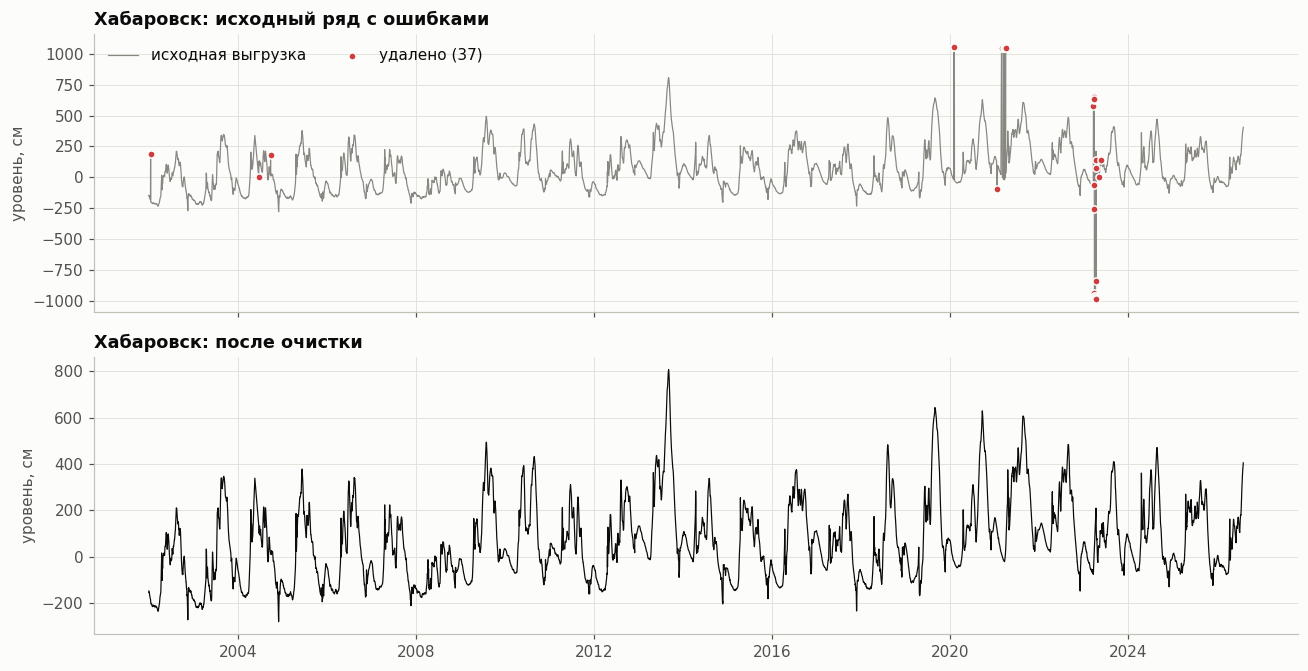

In [7]:
s_raw = raw_levels['khabarovsk'][START:END]
bad_k = removed[removed['пост'] == 'Хабаровск']
fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), sharex=True, gridspec_kw={'height_ratios': [1, 1]})
axes[0].plot(s_raw.index, s_raw.values, color=MUTED, lw=0.8, label='исходная выгрузка')
axes[0].scatter(bad_k.index, bad_k['значение, см'], s=22, color='#d03b3b', zorder=3,
                edgecolor=SURF, linewidth=1, label=f'удалено ({len(bad_k)})')
axes[0].set_title('Хабаровск: исходный ряд с ошибками')
axes[0].legend(loc='upper left', ncol=2)
axes[1].plot(clean.index, clean['level_khabarovsk'], color=INK, lw=0.8)
axes[1].set_title('Хабаровск: после очистки')
for ax in axes:
    ax.set_ylabel('уровень, см')
fig.tight_layout()
show(fig, '01_cleaning_khabarovsk.png')

### 2.3 Погода: NASA POWER (Хабаровск) и ERA5 (бассейн)

Файлы лежат в `data/raw`. Если какого-то нет, он скачивается из открытого API. У Open-Meteo есть лимит запросов в минуту: при ответе 429 код ждёт минуту и повторяет запрос.

> Нюанс NASA POWER: сейчас API отдаёт осадки, умноженные на 24 (средняя 47 мм/сут вместо 2). После деления на 24 значения совпадают с исходным датасетом проекта до сотых. Поправка в коде срабатывает только при явно завышенных значениях.

In [8]:
def load_era5(name):
    f = RAW / f'era5_{name}.csv'
    if not f.exists():
        pg_lstm.fetch_era5(name, '2001-09-01', END).rename_axis('time').to_csv(f)
    return pd.read_csv(f, parse_dates=['time']).set_index('time')


def load_nasa_power():
    f = RAW / 'nasa_power_khabarovsk.csv'
    if not f.exists():
        r = requests.get('https://power.larc.nasa.gov/api/temporal/daily/point', timeout=180, params=dict(
            parameters='T2M,PRECTOTCORR,PS,WS2M,RH2M', community='RE', latitude=48.48, longitude=135.07,
            start='20010101', end=END.strftime('%Y%m%d'), format='JSON'))
        r.raise_for_status()
        p = pd.DataFrame(r.json()['properties']['parameter'])
        p.index = pd.to_datetime(p.index, format='%Y%m%d')
        p.rename_axis('date').to_csv(f)
    p = pd.read_csv(f, parse_dates=['date']).set_index('date').replace(-999, np.nan)
    if p['PRECTOTCORR'].mean() > 20:          # осадки пришли ×24
        p['PRECTOTCORR'] = p['PRECTOTCORR'] / 24
    return p.rename(columns={'T2M': 'temp', 'PRECTOTCORR': 'precip', 'PS': 'pressure',
                             'WS2M': 'wind', 'RH2M': 'humidity'})[['temp', 'precip', 'pressure', 'wind', 'humidity']]


era5 = {n: load_era5(n) for n in pg_lstm.ERA5_POINTS}
local = load_nasa_power().reindex(DAYS).interpolate('time', limit_direction='both').round(2)
print('ERA5:', {n: f'{e.index.min().date()}…{e.index.max().date()}' for n, e in list(era5.items())[:2]}, '…')
print('NASA POWER, пропусков после заполнения:', int(local.isna().sum().sum()))

ERA5: {'khabarovsk': '2001-09-01…2026-10-24', 'birobidzhan': '2001-09-01…2026-10-24'} …
NASA POWER, пропусков после заполнения: 0


### 2.4 Физический признак: снег и водоотдача (модель градусо-дней)

Весенний подъём Амура — это талая вода, которая копилась всю зиму. Снегозапас сеть не может «увидеть» в погоде за последние 60 суток, поэтому считаем его заранее простой физической моделью (функция `pg_lstm.snow_model`):

$$SWE_t = SWE_{t-1} + P^{снег}_t - M_t,\qquad M_t = \min\big(SWE_{t-1}+P^{снег}_t,\; DDF\cdot\max(T_t - T_0,\,0)\big)$$

* $SWE$ — запас воды в снеге, мм;
* $P^{снег}$ — твёрдые осадки (осадки минус дождь);
* $DDF = 3$ мм/(°C·сут) — коэффициент стаивания, типичный для открытой местности;
* $T_0 = 0$ °C — порог таяния.

**Водоотдача** = дождь + талая вода, то есть сколько воды реально поступило на поверхность бассейна за сутки. Признаки усредняются по четырём частям бассейна.

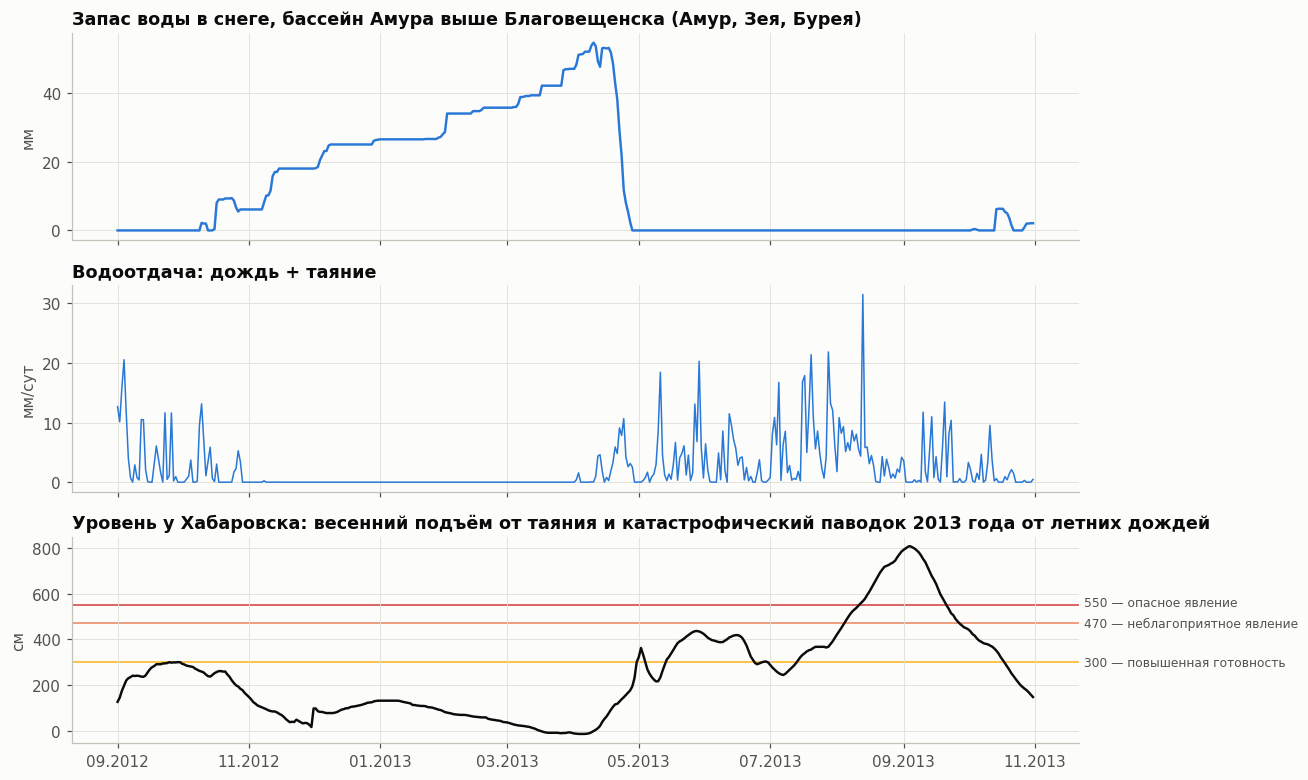

In [9]:
basin = pg_lstm.basin_weather(era5, DAYS)
w = slice('2012-09-01', '2013-10-31')
fig, axes = plt.subplots(3, 1, figsize=(12, 7.2), sharex=True)
axes[0].plot(basin.loc[w].index, basin.loc[w, 'amur_swe'], color='#2a78d6')
axes[0].set_title('Запас воды в снеге, бассейн Амура выше Благовещенска (Амур, Зея, Бурея)')
axes[0].set_ylabel('мм')
axes[1].plot(basin.loc[w].index, basin.loc[w, 'amur_water_input'], color='#2a78d6', lw=1)
axes[1].set_title('Водоотдача: дождь + таяние')
axes[1].set_ylabel('мм/сут')
axes[2].plot(clean.loc[w].index, clean.loc[w, 'level_khabarovsk'], color=INK)
thresholds(axes[2])
axes[2].set_title('Уровень у Хабаровска: весенний подъём от таяния и катастрофический паводок 2013 года от летних дождей')
axes[2].set_ylabel('см')
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
fig.tight_layout()
show(fig, '02_snow_model_2013.png')

### 2.5 Итоговый чистый датасет

Одна таблица на каждые сутки периода, без пропусков. Сохраняется в `data/amur_khabarovsk_clean.csv`. Это общий файл для командного проекта.

| Колонка | Что это | Ед. |
|---|---|---|
| `date` | дата | — |
| `level_khabarovsk`, `level_blagoveshchensk`, `level_poyarkovo`, `level_leninskoe` | уровень воды над нулём поста | см |
| `level_*_filled` | 1 — значение восстановлено интерполяцией (ошибка или пропуск в источнике), 0 — наблюдение | — |
| `temp`, `precip`, `pressure`, `wind`, `humidity` | погода в Хабаровске (NASA POWER), как в исходном датасете | °C, мм/сут, кПа, м/с, % |
| `{local,amur,sungari,ussuri}_temp` | средняя температура по части бассейна (ERA5) | °C |
| `{…}_precip` | осадки | мм/сут |
| `{…}_water_input` | водоотдача: дождь + таяние снега | мм/сут |
| `{…}_swe` | запас воды в снеге | мм |

In [10]:
clean = clean.join(local).join(basin)
clean.to_csv(BASE / 'data' / 'amur_khabarovsk_clean.csv')
print('Сохранено: data/amur_khabarovsk_clean.csv', clean.shape)
display(clean.describe().T[['min', 'mean', 'max']].round(1))

Сохранено: data/amur_khabarovsk_clean.csv (8979, 29)


,min,mean,max
level_khabarovsk,-279.0,67.6,807.0
level_khabarovsk_filled,0.0,0.0,1.0
level_blagoveshchensk,-113.0,127.3,860.0
level_blagoveshchensk_filled,0.0,0.1,1.0
level_poyarkovo,-202.0,124.8,833.0
level_poyarkovo_filled,0.0,0.2,1.0
level_leninskoe,-61.0,297.1,1044.0
level_leninskoe_filled,0.0,0.1,1.0
temp,-40.1,1.5,29.1
precip,0.0,2.0,62.8


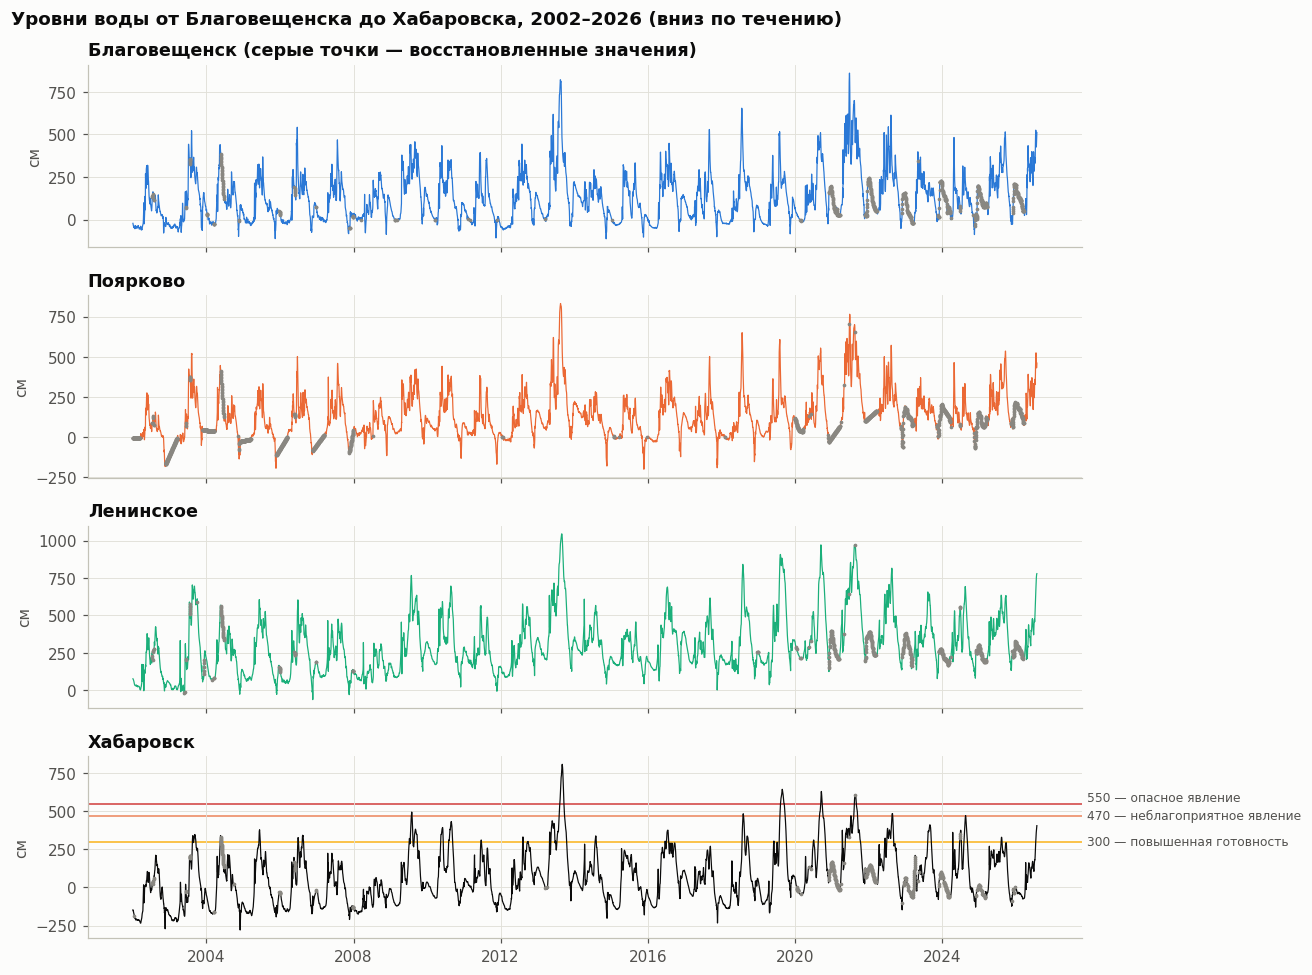

In [11]:
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, g in zip(axes, ['blagoveshchensk', 'poyarkovo', 'leninskoe', 'khabarovsk']):
    ax.plot(clean.index, clean[f'level_{g}'], color=GAUGE_COL[g], lw=0.8)
    f = clean[f'level_{g}_filled'] == 1
    ax.scatter(clean.index[f], clean.loc[f, f'level_{g}'], s=2, color=MUTED, zorder=3)
    ax.set_title(GAUGE_RU[g] + (' (серые точки — восстановленные значения)' if g == 'blagoveshchensk' else ''))
    ax.set_ylabel('см')
thresholds(axes[-1])
fig.suptitle('Уровни воды от Благовещенска до Хабаровска, 2002–2026 (вниз по течению)', x=0.01, ha='left',
             fontweight='bold')
fig.tight_layout()
show(fig, '03_gauges_overview.png')

## 3. Физика реки

### 3.1 Время добегания волны

Подъём на верхнем посту доходит до Хабаровска с запаздыванием. Оценим его по кросс-корреляции **5-суточных изменений** уровня: изменения, а не сами уровни, чтобы общая сезонность не давала ложной связи. Берём открытую воду (май–октябрь), только наблюдённые значения и период обучения 2002–2015.

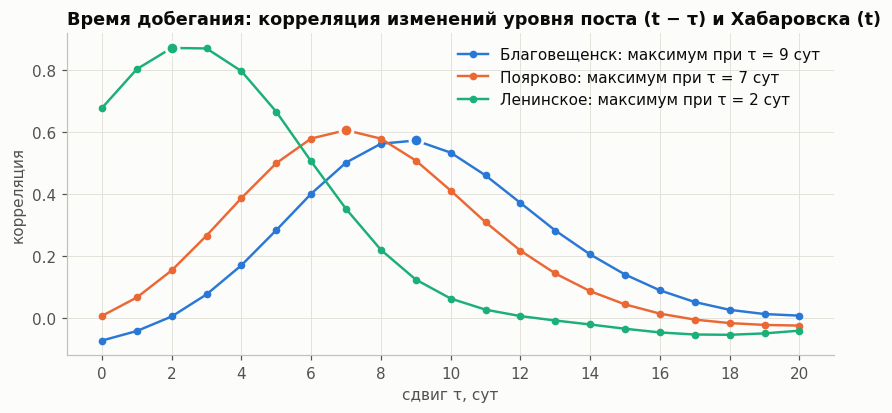

In [12]:
H = clean['level_khabarovsk']
OBS = clean['level_khabarovsk_filled'] == 0
OPEN = [5, 6, 7, 8, 9, 10]                      # месяцы открытой воды
is_open = clean.index.month.isin(OPEN)
is_train = clean.index <= TRAIN_END

xcorr = pd.DataFrame(index=range(0, 21))
for p in pg_lstm.UPSTREAM:
    u, uf = clean[f'level_{p}'], clean[f'level_{p}_filled']
    for tau in xcorr.index:
        m = is_open & is_train & OBS & (uf.shift(tau) == 0)
        xcorr.loc[tau, p] = H.diff(5)[m].corr(u.shift(tau).diff(5)[m])
xcorr = xcorr.astype(float)
lag_best = xcorr.idxmax()

fig, ax = plt.subplots(figsize=(9, 3.8))
for p in pg_lstm.UPSTREAM:
    ax.plot(xcorr.index, xcorr[p], color=GAUGE_COL[p], marker='o', ms=4,
            label=f'{GAUGE_RU[p]}: максимум при τ = {lag_best[p]} сут')
    ax.scatter(lag_best[p], xcorr[p].max(), s=70, color=GAUGE_COL[p], edgecolor=SURF, linewidth=2, zorder=4)
ax.set_xlabel('сдвиг τ, сут')
ax.set_xticks(range(0, 21, 2))
ax.set_ylabel('корреляция')
ax.set_title('Время добегания: корреляция изменений уровня поста (t − τ) и Хабаровска (t)')
ax.legend()
show(fig, '04_travel_time.png')

### 3.2 Уравнение маршрутизации (Маскингам / Калинин–Милюков)

Участок реки работает как ёмкость: **уравнение неразрывности** $\frac{dW}{dt} = Q_{вх} - Q_{вых}$ вместе с линейной связью запаса и расхода $W = K\,[xQ_{вх} + (1-x)Q_{вых}]$ даёт классическую схему Маскингама (у Калинина–Милюкова $x = 0$):

$$Q_{вых}(t) = C_0 Q_{вх}(t) + C_1 Q_{вх}(t-1) + C_2 Q_{вых}(t-1),\qquad C_0 + C_1 + C_2 = 1.$$

Расходов у нас нет, есть уровни. Около рабочей точки кривая расходов $Q(H)$ почти линейна, поэтому то же уравнение выполняется **для суточных приращений уровня**, с запаздыванием τ от каждого поста:

$$\Delta H_{Х}(t) = \varphi\,\Delta H_{Х}(t-1) + \sum_j \big[a_{j0}\,\Delta H_j(t-\tau_j) + a_{j1}\,\Delta H_j(t-\tau_j-1)\big] + \varepsilon$$

* $\varphi$ ($= C_2$) — «память» участка, то есть аккумуляция воды в русле и пойме; $K = 1/(1-\varphi)$ — характерное время сглаживания волны, сут;
* $a_j$ — насколько подъём на посту $j$ передаётся в Хабаровск;
* $\varepsilon$ — то, что физика не объясняет: боковой приток (Уссури, Сунгари ниже поста, местные реки) и лёд. Это остаётся нейросети.

Коэффициенты подбираются методом наименьших квадратов на открытой воде 2002–2015. **Важно для прогноза:** на горизонте $h$ известны только посты, у которых $\tau_j \ge h$ (их сигнал уже прошёл). Поэтому физических моделей три:

* **m1** ($h \le 2$): Ленинское, Поярково, Благовещенск;
* **m2** ($h \le 5$): Поярково, Благовещенск;
* **m3** ($h \le 7$): Благовещенск.

Член $\varphi$ сам даёт часть запаздывания, поэтому для Поярково и Благовещенска оптимальные τ в уравнении получаются короче, чем по кросс-корреляции: 5 и 7 суток вместо 7 и 9 (подобраны по R² на обучении).

In [13]:
TAU = {'leninskoe': 2, 'poyarkovo': 5, 'blagoveshchensk': 7}     # τ в уравнении маршрутизации, сут
ROUTING_SETS = [('m1', ['leninskoe', 'poyarkovo', 'blagoveshchensk'], 2),
                ('m2', ['poyarkovo', 'blagoveshchensk'], 5),
                ('m3', ['blagoveshchensk'], 7)]
dH = H.diff()


def fit_routing(posts, hmax):
    """Калибровка уравнения маршрутизации МНК на открытой воде 2002–2015."""
    cols, ok = [], OBS & OBS.shift(2, fill_value=False)
    for p in posts:
        for d in (0, 1):
            cols.append(clean[f'level_{p}'].diff().shift(TAU[p] + d))
            ok &= clean[f'level_{p}_filled'].shift(TAU[p] + d + 1, fill_value=1) == 0
    U = pd.concat(cols, axis=1).values
    X = np.column_stack([U, dH.shift(1).values])
    good = ~np.isnan(X).any(1) & ~np.isnan(dH.values) & (ok & is_open).values
    m_tr, m_te = good & is_train, good & ~is_train
    beta = np.linalg.lstsq(X[m_tr], dH.values[m_tr], rcond=None)[0]
    a, phi = beta[:-1], beta[-1]
    r2 = lambda m: 1 - np.var(dH.values[m] - X[m] @ beta) / np.var(dH.values[m])
    return dict(posts=posts, tau={p: TAU[p] for p in posts}, hmax=hmax, phi=float(phi), a=a.tolist(),
                sigma=float(np.std(dH.values[m_tr] - X[m_tr] @ beta)),
                u=np.nan_to_num(U @ a),                               # вклад постов в ΔH(t), см
                valid=(ok & is_open).values & ~np.isnan(U).any(1),     # где уравнение применимо
                r2_train=r2(m_tr), r2_test=r2(m_te))


ROUTING = {name: fit_routing(posts, hmax) for name, posts, hmax in ROUTING_SETS}
# то, что нужно модулю pg_lstm для прогноза (без служебных рядов)
ROUTING_CFG = {n: {k: r[k] for k in ('posts', 'tau', 'hmax', 'phi', 'a', 'sigma')} for n, r in ROUTING.items()}
SIG_R = float(np.mean([r['sigma'] for r in ROUTING.values()]))

display(pd.DataFrame([{
    'модель': n, 'горизонты': f'h ≤ {hmax}', 'посты (τ, сут)': ', '.join(f'{GAUGE_RU[p]} ({TAU[p]})' for p in posts),
    'φ': round(ROUTING[n]['phi'], 3), 'K = 1/(1−φ), сут': round(1 / (1 - ROUTING[n]['phi']), 1),
    'σ невязки, см': round(ROUTING[n]['sigma'], 2),
    'R² ΔH, 2002–2015': round(ROUTING[n]['r2_train'], 3), 'R² ΔH, 2016–2026': round(ROUTING[n]['r2_test'], 3),
} for n, posts, hmax in ROUTING_SETS]).set_index('модель'))

,горизонты,"посты (τ, сут)",φ,"K = 1/(1−φ), сут","σ невязки, см","R² ΔH, 2002–2015","R² ΔH, 2016–2026"
модель,,,,,,,
m1,h ≤ 2,"Ленинское (2), Поярково (5), Благовещенск (7)",0.462,1.9,4.75,0.798,0.853
m2,h ≤ 5,"Поярково (5), Благовещенск (7)",0.709,3.4,5.56,0.723,0.808
m3,h ≤ 7,Благовещенск (7),0.714,3.5,5.64,0.715,0.792


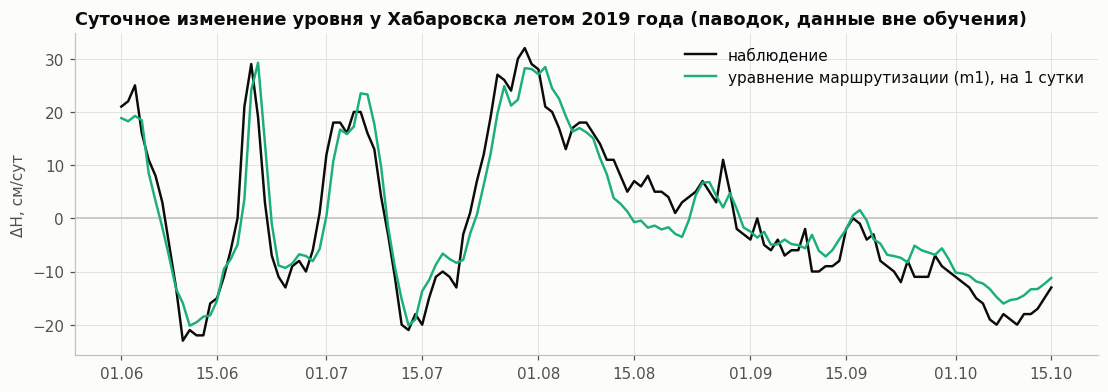

In [14]:
w = (clean.index >= '2019-06-01') & (clean.index <= '2019-10-15')
phys_dh = ROUTING['m1']['phi'] * dH.shift(1) + ROUTING['m1']['u']
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.axhline(0, color=AXIS, lw=1)
ax.plot(clean.index[w], dH[w], color=INK, label='наблюдение')
ax.plot(clean.index[w], phys_dh[w], color=COL['Физическая модель'], label='уравнение маршрутизации (m1), на 1 сутки')
ax.set_title('Суточное изменение уровня у Хабаровска летом 2019 года (паводок, данные вне обучения)')
ax.set_ylabel('ΔH, см/сут')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
ax.legend(loc='upper right')
show(fig, '05_routing_2019.png')

### 3.3 Предельная скорость изменения уровня

Большая река не может подняться или упасть на метр за сутки в июле: мешает инерция массы воды. Из истории 2002–2015 берём для каждого месяца 99,5%-квантиль модуля суточного изменения $\Delta H_{max}$. Это второе физическое ограничение. В апреле (ледоход) и ноябре (ледостав) предел намного выше, потому что ледовые заторы дают резкие скачки.

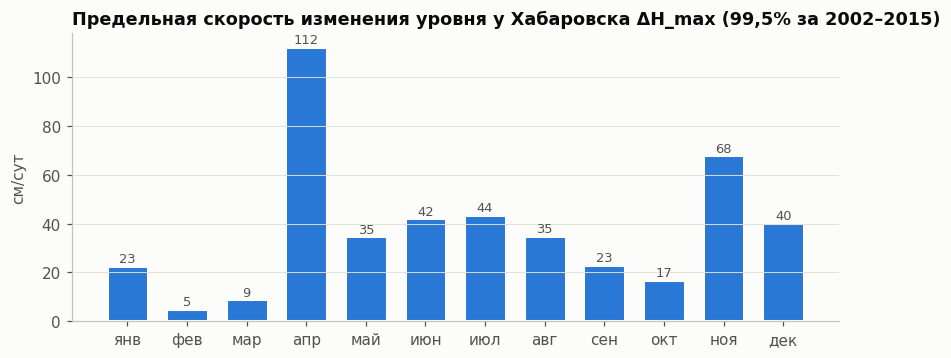

In [15]:
ok_d = OBS & OBS.shift(1, fill_value=False) & is_train
DMAX = dH[ok_d].abs().groupby(clean.index[ok_d].month).quantile(0.995)
DMAX_DAY = clean.index.month.map(DMAX).values.astype(float)

fig, ax = plt.subplots(figsize=(9, 3.4))
months = ['янв', 'фев', 'мар', 'апр', 'май', 'июн', 'июл', 'авг', 'сен', 'окт', 'ноя', 'дек']
bars = ax.bar(months, DMAX.values, color='#2a78d6', width=0.7, edgecolor=SURF, linewidth=2)
for b, v in zip(bars, DMAX.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 1.5, f'{v:.0f}', ha='center', fontsize=8.5, color=INK2)
ax.set_ylabel('см/сут')
ax.set_title('Предельная скорость изменения уровня у Хабаровска ΔH_max (99,5% за 2002–2015)')
ax.grid(axis='x', visible=False)
show(fig, '06_rate_limit.png')

## 4. Модель PG-LSTM

Физика входит в модель **двумя путями**. Так устроены физически-управляемые сети PGNN (Karpatne et al., 2017).

**1. Физический прогноз на входе и на выходе.** Уравнение маршрутизации (п. 3.2) само даёт прогноз на 14 суток $\Phi_h$:
* на $h \le 7$ — по уже наблюдённым приращениям постов выше по течению;
* дальше — затухание волны с коэффициентом $\varphi$.

Сеть получает этот прогноз вместе с историей и предсказывает **поправку** к нему:

$$\hat H_{t+h} = H_t + \Phi_h + 50\cdot g_\theta(x_{t-59..t},\,\Phi)_h .$$

Где физика права, поправка маленькая. Где физика ничего не знает (лёд, боковой приток Уссури и Сунгари, $h > 7$), работает сеть.

**2. Физические штрафы в функции потерь.** Сеть наказывается, если её прогнозная траектория нарушает уравнение маршрутизации или предельную скорость:

$$\mathcal L = \underbrace{\frac{1}{|M|}\sum_{h} \Big(\frac{\hat H_{t+h} - H_{t+h}}{50}\Big)^2}_{\text{данные}} \;+\; \lambda\underbrace{\frac{1}{|P|}\sum_{h\le 7}\Big(\frac{r_h}{\sigma_r}\Big)^2}_{\text{маршрутизация}} \;+\; \mu\underbrace{\frac{1}{14}\sum_h \Big(\frac{\max(|\Delta\hat H_h| - \Delta H_{max},\,0)}{\sigma_r}\Big)^2}_{\text{скорость}}$$

* $r_h = \Delta\hat H_h - \varphi\,\Delta\hat H_{h-1} - \sum_j a_j\,\Delta H_j(t+h-\tau_j)$ — невязка уравнения маршрутизации **на траектории сети**. Приращения постов при $h \le \tau_j$ уже наблюдены, поэтому штраф честный, без заглядывания в будущее;
* $M$ — только наблюдённые цели (восстановленные значения не учитываются);
* $P$ — открытая вода, верхние посты наблюдены, $h \le 7$;
* $\sigma_r \approx 5$ см — типичная невязка уравнения на реальных данных, нормировка делает штрафы соизмеримыми с ошибкой;
* **λ** — вес уравнения маршрутизации, подбирается на валидации;
* **μ = 30** — вес предельной скорости. Штраф включается только при превышении предела, поэтому вес можно сделать большим: на обычных прогнозах он ни на что не влияет и работает почти как жёсткое ограничение. При μ = λ сеть давала излом траектории на стыке 7-х и 8-х суток, где заканчивается действие уравнения маршрутизации.

**Вход сети:** окно из 60 последних суток по 22 признакам:
* уровни 4 постов и суточное изменение уровня в Хабаровске;
* флаги «значение восстановлено» для 3 верхних постов;
* по 4 частям бассейна: температура, водоотдача и запас воды в снеге;
* синус и косинус дня года.

Признаки масштабируются по периоду обучения.

**Архитектура:** двухслойная LSTM (64 нейрона, dropout 0,2), затем полносвязный слой: последнее состояние LSTM плюс $\Phi$ → 14 поправок.

**Три ступени для сравнения** (вклад каждого пути физики):

| Модель | Физический прогноз на входе | Физические штрафы |
|---|---|---|
| LSTM | — | — |
| LSTM + физ. вход | ✓ | — (λ = μ = 0) |
| **PG-LSTM** | ✓ | ✓ (λ выбирается на валидации, μ = 30) |

**Деление по времени** (без перемешивания, чтобы не подглядывать в будущее):
* обучение 2002–2015;
* валидация 2016–2018 — выбор λ и ранняя остановка;
* **тест 2019–2026** — крупные паводки 2019, 2020, 2021 и 2026 годов.

In [16]:
WINDOW, HZ, SCALE = pg_lstm.WINDOW, pg_lstm.HORIZON, pg_lstm.SCALE
ARCH = dict(hidden=64, layers=2, dropout=0.2)
H_MODEL = {h: next(n for n, r in ROUTING.items() if h <= r['hmax']) for h in range(1, 8)}

feat = pg_lstm.build_features(clean)
FEATURES = list(feat.columns)
f_mean, f_std = feat[is_train].mean(), feat[is_train].std().replace(0, 1)
Xf = ((feat - f_mean) / f_std).values.astype(np.float32)
Hv, OBSv, dHv = H.values, OBS.values, np.nan_to_num(dH.values)
N, dates = len(clean), clean.index


def make_samples(t_idx):
    """Окна истории, цели, физический прогноз и всё для штрафов — для дней прогноза t_idx."""
    t_idx = np.asarray(t_idx)
    win = t_idx[:, None] + np.arange(-WINDOW + 1, 1)[None]
    fut = t_idx[:, None] + np.arange(1, HZ + 1)[None]
    U, PHI = pg_lstm.routing_terms(clean, ROUTING_CFG, t_idx)
    PM = np.zeros((len(t_idx), HZ))
    for h, name in H_MODEL.items():
        PM[:, h - 1] = ROUTING[name]['valid'][t_idx + h]
    PHYS = pg_lstm.routing_forecast(clean, ROUTING_CFG, t_idx) / SCALE
    arrays = (Xf[win], (Hv[fut] - Hv[t_idx, None]) / SCALE, OBSv[fut], U, PHI, PM,
              DMAX_DAY[fut], Hv[t_idx], dHv[t_idx], PHYS)
    return [torch.tensor(np.asarray(a, dtype=np.float32)) for a in arrays]
    #       0 X   1 Y   2 M   3 U   4 PHI   5 PM   6 DM   7 H0   8 D0   9 PHYS


idx = np.arange(WINDOW - 1, N - HZ)
tr_idx = idx[dates[idx + HZ] <= TRAIN_END]
va_idx = idx[(dates[idx] > TRAIN_END) & (dates[idx + HZ] <= VAL_END)]
te_idx = idx[dates[idx] > VAL_END]
TR, VA, TE = make_samples(tr_idx), make_samples(va_idx), make_samples(te_idx)
print(f'Признаков: {len(FEATURES)}. Примеров: обучение {len(tr_idx)}, валидация {len(va_idx)}, '
      f'тест {len(te_idx)} ({dates[te_idx[0]].date()} — {dates[te_idx[-1]].date()})')

Признаков: 22. Примеров: обучение 5040, валидация 1082, тест 2756 (2019-01-01 — 2026-07-18)


In [17]:
def loss_terms(pred, Y, M, U, PHI, PM, DM, H0, D0):
    """Три слагаемых функции потерь: данные, маршрутизация, предельная скорость."""
    data = ((pred - Y) ** 2 * M).sum() / M.sum().clamp(min=1)
    d = torch.diff(pred * SCALE, dim=1, prepend=torch.zeros_like(pred[:, :1]))   # ΔĤ_h, см
    d_prev = torch.cat([D0[:, None], d[:, :-1]], dim=1)                          # ΔĤ_{h-1}
    r = d - PHI * d_prev - U                                                     # невязка уравнения
    phys = ((r / SIG_R) ** 2 * PM).sum() / PM.sum().clamp(min=1)
    rate = ((torch.relu(d.abs() - DM) / SIG_R) ** 2).mean()
    return data, phys, rate


def train_one(lam, mu, seed, physics_input=True, epochs=60, patience=10, batch=128):
    torch.manual_seed(seed)
    model = pg_lstm.PGLSTM(len(FEATURES), physics_input=physics_input, **ARCH)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
    best, best_state, wait, hist = np.inf, None, 0, []
    for ep in range(epochs):
        model.train()
        for bi in torch.randperm(len(TR[0])).split(batch):
            b = [a[bi] for a in TR]
            l_data, l_phys, l_rate = loss_terms(model(b[0], b[9]), *b[1:9])
            loss = l_data + lam * l_phys + mu * l_rate
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            p = model(VA[0], VA[9])
            v_phys = loss_terms(p, *VA[1:9])[1].item()
            mae = (((p - VA[1]).abs() * VA[2]).sum() / VA[2].sum()).item() * SCALE
        hist.append((mae, v_phys))
        if mae < best - 0.01:                     # ранняя остановка по MAE на валидации
            best, best_state, wait = mae, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, hist


def predict(models, D):
    """Прогноз ансамбля: приращения уровня к H_t, см, форма (n, 14)."""
    with torch.no_grad():
        return torch.stack([m(D[0], D[9]) for m in models]).mean(0).numpy() * SCALE

## 5. Обучение и выбор веса физики λ

Для каждой модели обучаем 5 сетей с разными начальными весами (сидами) и усредняем их прогнозы. Это **ансамбль**: одиночные сети заметно расходятся на дальних горизонтах, и без усреднения сравнение моделей было бы лотереей.

Вес уравнения маршрутизации в PG-LSTM перебираем: λ ∈ {1, 3, 10}, вес скорости μ = 30. **λ выбираем по валидации 2016–2018**, тест до этого момента не трогаем.

In [18]:
MU = 30                                          # вес штрафа за превышение предельной скорости
CONFIGS = {'LSTM': (False, 0, 0), 'LSTM + физ. вход': (True, 0, 0)}   # (физ. вход, λ, μ)
for lam in ([1] if FAST else [1, 3, 10]):
    CONFIGS[f'PG-LSTM, λ = {lam}'] = (True, lam, MU)
SEEDS = range(3) if FAST else range(5)

runs = {}
t0 = time.time()
for name, (phys_in, lam, mu) in CONFIGS.items():
    runs[name] = [train_one(lam, mu, s, phys_in) for s in SEEDS]
    print(f'{name:<18} обучено {len(SEEDS)} сетей, эпох: {[len(h) for _, h in runs[name]]}, '
          f'прошло {time.time() - t0:.0f} с')
models = {name: [m for m, _ in r] for name, r in runs.items()}

LSTM               обучено 5 сетей, эпох: [15, 15, 17, 17, 14], прошло 127 с


LSTM + физ. вход   обучено 5 сетей, эпох: [16, 17, 17, 16, 19], прошло 272 с


PG-LSTM, λ = 1     обучено 5 сетей, эпох: [29, 23, 25, 24, 24], прошло 474 с


PG-LSTM, λ = 3     обучено 5 сетей, эпох: [34, 27, 25, 31, 32], прошло 713 с


PG-LSTM, λ = 10    обучено 5 сетей, эпох: [42, 44, 43, 42, 38], прошло 1049 с


In [19]:
def mae_by_h(pred, D):
    err, M = pred - D[1].numpy() * SCALE, D[2].numpy().astype(bool)
    return np.array([np.abs(err[M[:, h], h]).mean() for h in range(HZ)])


rows = []
for name in CONFIGS:
    p = predict(models[name], VA)
    mae = mae_by_h(p, VA)
    with torch.no_grad():
        ph = loss_terms(torch.tensor(p / SCALE, dtype=torch.float32), *VA[1:9])[1].item()
    rows.append({'модель': name, 'MAE h=1': mae[0], 'MAE h=3': mae[2], 'MAE h=7': mae[6], 'MAE h=14': mae[13],
                 'MAE средн. 1–14': mae.mean(), 'невязка физики (норм.)': ph})
val_table = pd.DataFrame(rows).set_index('модель').round(2)
PG_NAME = val_table.loc[[n for n in CONFIGS if n.startswith('PG')], 'MAE средн. 1–14'].idxmin()
LAM = CONFIGS[PG_NAME][1]
models['PG-LSTM'] = models[PG_NAME]
print('Валидация 2016–2018, ансамбли, MAE в см:')
display(val_table)
print(f'Выбрана модель «{PG_NAME}» — наименьшая средняя MAE на валидации среди вариантов PG-LSTM')

Валидация 2016–2018, ансамбли, MAE в см:


,MAE h=1,MAE h=3,MAE h=7,MAE h=14,MAE средн. 1–14,невязка физики (норм.)
модель,,,,,,
LSTM,4.98,12.62,20.440001,31.750000,20.360001,0.48
LSTM + физ. вход,3.64,9.93,18.680000,31.700001,18.790001,0.22
"PG-LSTM, λ = 1",3.41,9.61,20.530001,31.799999,19.240000,0.02
"PG-LSTM, λ = 3",3.40,9.82,21.920000,31.690001,19.690001,0.01
"PG-LSTM, λ = 10",3.42,9.98,22.799999,30.760000,19.629999,0.00


Выбрана модель «PG-LSTM, λ = 1» — наименьшая средняя MAE на валидации среди вариантов PG-LSTM


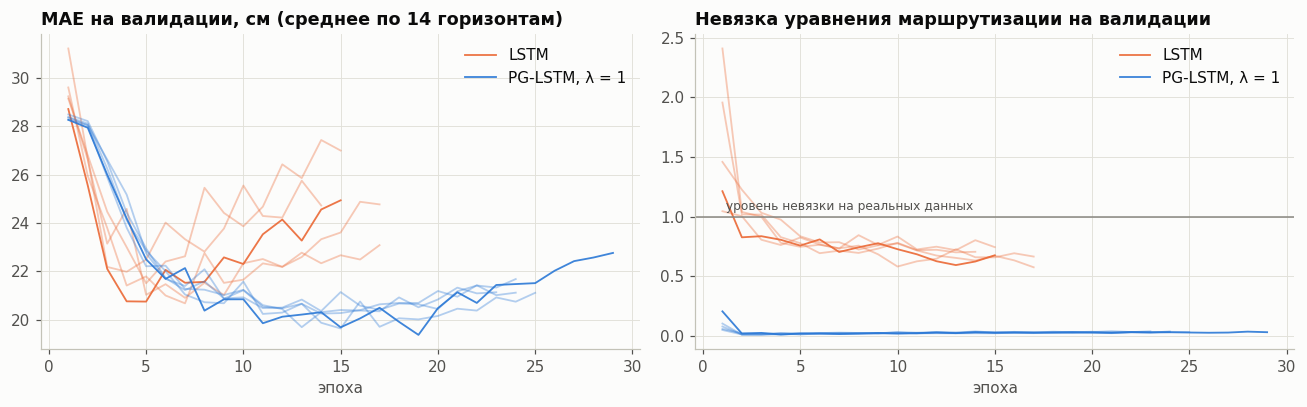

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, label in [('LSTM', 'LSTM'), (PG_NAME, 'PG-LSTM')]:
    for i, (_, hist) in enumerate(runs[name]):
        h = np.array(hist)
        kw = dict(color=COL[label], lw=1.2, alpha=0.9 if i == 0 else 0.35, label=name if i == 0 else None)
        axes[0].plot(np.arange(1, len(h) + 1), h[:, 0], **kw)
        axes[1].plot(np.arange(1, len(h) + 1), h[:, 1], **kw)
axes[0].set_title('MAE на валидации, см (среднее по 14 горизонтам)')
axes[1].set_title('Невязка уравнения маршрутизации на валидации')
axes[1].axhline(1, color=MUTED, lw=1)
axes[1].text(1, 1.03, ' уровень невязки на реальных данных', color=INK2, fontsize=8, va='bottom')
for ax in axes:
    ax.set_xlabel('эпоха')
    ax.legend()
fig.tight_layout()
show(fig, '07_training_curves.png')

## 6. Тестирование на 2019–2026 годах

Сравниваем пять прогнозов на одних и тех же днях теста:

| Модель | Как прогнозирует |
|---|---|
| **Инерционный** | «через h суток будет как сегодня». Минимальный порог: модель, которая его не бьёт, бесполезна |
| **Физическая модель** | только уравнение маршрутизации $\Phi_h$ |
| **LSTM** | сеть только на данных |
| **LSTM + физ. вход** | сеть поправляет физический прогноз, без штрафов |
| **PG-LSTM** | сеть поправляет физический прогноз и штрафуется за нарушение физики |

**Метрики** считаются для каждого горизонта $h$ по наблюдённым (не восстановленным) значениям:
* **MAE** — средняя абсолютная ошибка, см;
* **S** (RMSE) — среднеквадратичная ошибка, см;
* **NSE** — коэффициент Нэша–Сатклиффа (1 — идеально, 0 — не лучше среднего);
* **S/σΔ** — критерий Наставления по службе прогнозов Росгидромета (σΔ — разброс изменения уровня за время упреждения): методика **хорошая** при S/σΔ ≤ 0,50, **удовлетворительная** при ≤ 0,80;
* **P%** — обеспеченность: доля прогнозов с ошибкой не больше допустимой $\delta_{доп} = 0{,}674\,\sigma_\Delta$.

In [21]:
MODELS = ['Инерционный', 'Физическая модель', 'LSTM', 'LSTM + физ. вход', 'PG-LSTM']
PRED = {'Инерционный': np.zeros((len(te_idx), HZ)), 'Физическая модель': TE[9].numpy() * SCALE}
PRED.update({name: predict(models[name], TE) for name in ['LSTM', 'LSTM + физ. вход', 'PG-LSTM']})
Y_TE, M_TE, H0_TE = TE[1].numpy() * SCALE, TE[2].numpy().astype(bool), TE[7].numpy()


def metrics(pred, Y, M, H0):
    rows = []
    for h in range(HZ):
        m = M[:, h]
        e, dlt, lvl = pred[m, h] - Y[m, h], Y[m, h], H0[m] + Y[m, h]
        S_ = np.sqrt((e ** 2).sum() / (m.sum() - 1))
        sd = dlt.std(ddof=1)
        rows.append({'h': h + 1, 'MAE': np.abs(e).mean(), 'S (RMSE)': S_,
                     'NSE': 1 - (e ** 2).sum() / ((lvl - lvl.mean()) ** 2).sum(),
                     'S/σΔ': S_ / sd, 'P%': (np.abs(e) <= 0.674 * sd).mean() * 100})
    return pd.DataFrame(rows).set_index('h')


def grade(x):
    return 'хорошая' if x <= 0.5 else 'удовлетворительная' if x <= 0.8 else 'неудовлетворительная'


MET = {name: metrics(PRED[name], Y_TE, M_TE, H0_TE) for name in MODELS}
pd.concat(MET, names=['модель']).round(3).to_csv(MODEL_DIR / 'test_metrics.csv')
show_h = [1, 3, 5, 7, 10, 14]
print('MAE на тесте, см:')
display(pd.DataFrame({n: MET[n].loc[show_h, 'MAE'] for n in MODELS}).round(1))
print('S/σΔ на тесте:')
display(pd.DataFrame({n: MET[n].loc[show_h, 'S/σΔ'] for n in MODELS}).round(2))
print('PG-LSTM подробно:')
pg_tbl = MET['PG-LSTM'].loc[show_h].round(2)
pg_tbl['оценка'] = pg_tbl['S/σΔ'].map(grade)
display(pg_tbl)

MAE на тесте, см:


,Инерционный,Физическая модель,LSTM,LSTM + физ. вход,PG-LSTM
h,,,,,
1,7.9,4.100000,6.100000,4.400000,4.000000
3,21.7,11.700000,16.299999,12.100000,11.100000
5,33.6,20.100000,23.900000,19.600000,18.000000
7,43.6,28.299999,29.500000,25.600000,24.200001
10,56.6,40.799999,35.900002,32.900002,31.200001
14,70.9,57.099998,44.299999,42.400002,41.900002


S/σΔ на тесте:


,Инерционный,Физическая модель,LSTM,LSTM + физ. вход,PG-LSTM
h,,,,,
1,1.0,0.78,0.87,0.77,0.77
3,1.0,0.74,0.81,0.69,0.69
5,1.0,0.74,0.75,0.65,0.65
7,1.0,0.75,0.69,0.62,0.63
10,1.0,0.78,0.64,0.60,0.59
14,1.0,0.84,0.63,0.61,0.61


PG-LSTM подробно:


,MAE,S (RMSE),NSE,S/σΔ,P%,оценка
h,,,,,,
1,4.020000,10.00,1.00,0.77,92.49,удовлетворительная
3,11.080000,21.71,0.98,0.69,89.18,удовлетворительная
5,17.959999,29.79,0.97,0.65,84.08,удовлетворительная
7,24.200001,36.81,0.96,0.63,82.37,удовлетворительная
10,31.240000,44.44,0.94,0.59,80.98,удовлетворительная
14,41.939999,56.94,0.89,0.61,77.80,удовлетворительная


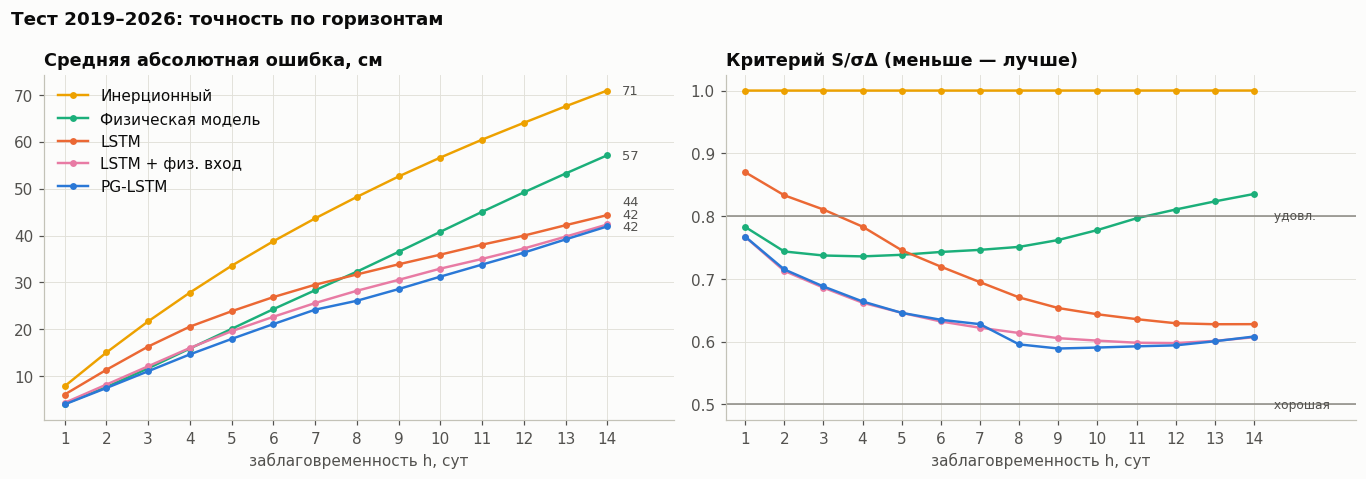

In [22]:
def end_labels(ax, x, values, gap):
    """Подписи значений у правого края без наложений."""
    last = -np.inf
    for v in sorted(values):
        y = max(v, last + gap)
        ax.text(x, y, f'{v:.0f}', color=INK2, fontsize=8.5, va='center')
        last = y


fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
hs = np.arange(1, HZ + 1)
for name in MODELS:
    axes[0].plot(hs, MET[name]['MAE'], color=COL[name], marker='o', ms=3.5, label=name)
    axes[1].plot(hs, MET[name]['S/σΔ'], color=COL[name], marker='o', ms=3.5, label=name)
end_labels(axes[0], 14.35, [MET[n].loc[14, 'MAE'] for n in MODELS], gap=2.6)
axes[0].set_title('Средняя абсолютная ошибка, см')
axes[1].set_title('Критерий S/σΔ (меньше — лучше)')
for v, name in [(0.5, 'хорошая'), (0.8, 'удовл.')]:
    axes[1].axhline(v, color=MUTED, lw=1)
    axes[1].text(14.4, v, f' {name}', color=INK2, fontsize=8, va='center')
for ax in axes:
    ax.set_xlabel('заблаговременность h, сут')
    ax.set_xticks(hs)
axes[0].set_xlim(0.5, 15.6)
axes[1].set_xlim(0.5, 16.6)
axes[0].legend(loc='upper left')
fig.suptitle('Тест 2019–2026: точность по горизонтам', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
show(fig, '08_metrics_by_horizon.png')

### 6.1 Физическая согласованность прогнозов

Метрики точности не показывают, **насколько физичен** прогноз. Проверим на тесте две вещи:
* среднюю невязку уравнения маршрутизации на прогнозной траектории ($h \le 7$, открытая вода). Для сравнения та же невязка у реального уровня;
* долю прогнозов, где суточный скачок уровня превышает исторический предел $\Delta H_{max}$ этого месяца.

In [23]:
def physics_check(pred_cm, D):
    U, PHI, PM, DM, D0 = (D[i].numpy() for i in (3, 4, 5, 6, 8))
    d = np.diff(pred_cm, axis=1, prepend=0)
    d_prev = np.concatenate([D0[:, None], d[:, :-1]], axis=1)
    r = np.abs(d - PHI * d_prev - U)[PM.astype(bool)]
    return r.mean(), (np.abs(d) > DM).mean() * 100


phys_tbl = pd.DataFrame({name: physics_check(PRED[name], TE) for name in ['LSTM', 'LSTM + физ. вход', 'PG-LSTM']},
                        index=['средняя |невязка| маршрутизации, см/сут', 'превышение ΔH_max, % прогнозов']).T
phys_tbl.loc['реальный уровень'] = [physics_check(Y_TE, TE)[0], np.nan]
display(phys_tbl.round(2))

,"средняя |невязка| маршрутизации, см/сут","превышение ΔH_max, % прогнозов"
LSTM,3.27,0.26
LSTM + физ. вход,2.09,0.22
PG-LSTM,0.61,0.17
реальный уровень,3.44,NaN


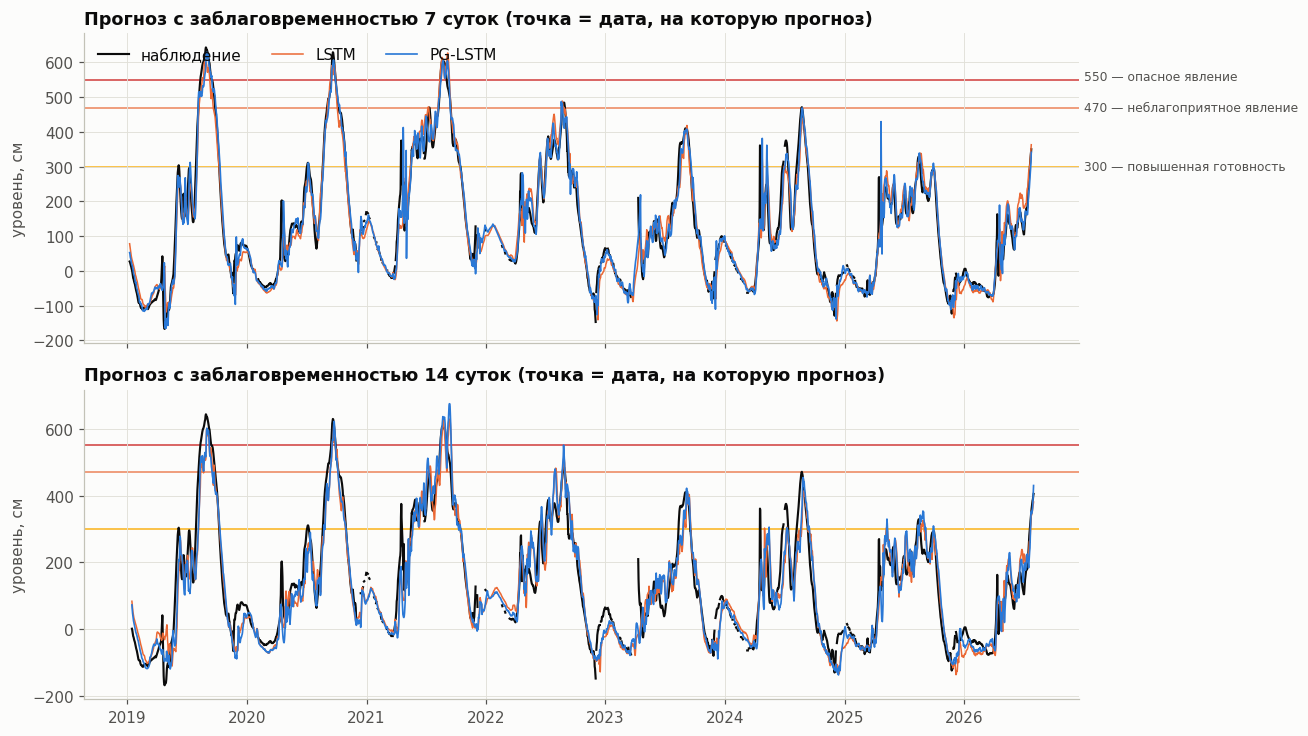

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.8), sharex=True)
t_dates = dates[te_idx]
for ax, h in zip(axes, [7, 14]):
    tgt = t_dates + pd.Timedelta(days=h)
    obs_lvl = np.where(M_TE[:, h - 1], H0_TE + Y_TE[:, h - 1], np.nan)
    ax.plot(tgt, obs_lvl, color=INK, lw=1.4, label='наблюдение')
    ax.plot(tgt, H0_TE + PRED['LSTM'][:, h - 1], color=COL['LSTM'], lw=1, label='LSTM')
    ax.plot(tgt, H0_TE + PRED['PG-LSTM'][:, h - 1], color=COL['PG-LSTM'], lw=1.1, label='PG-LSTM')
    thresholds(ax, labels=(h == 7))
    ax.set_title(f'Прогноз с заблаговременностью {h} суток (точка = дата, на которую прогноз)')
    ax.set_ylabel('уровень, см')
axes[0].legend(loc='upper left', ncol=3)
fig.tight_layout()
show(fig, '09_test_series.png')

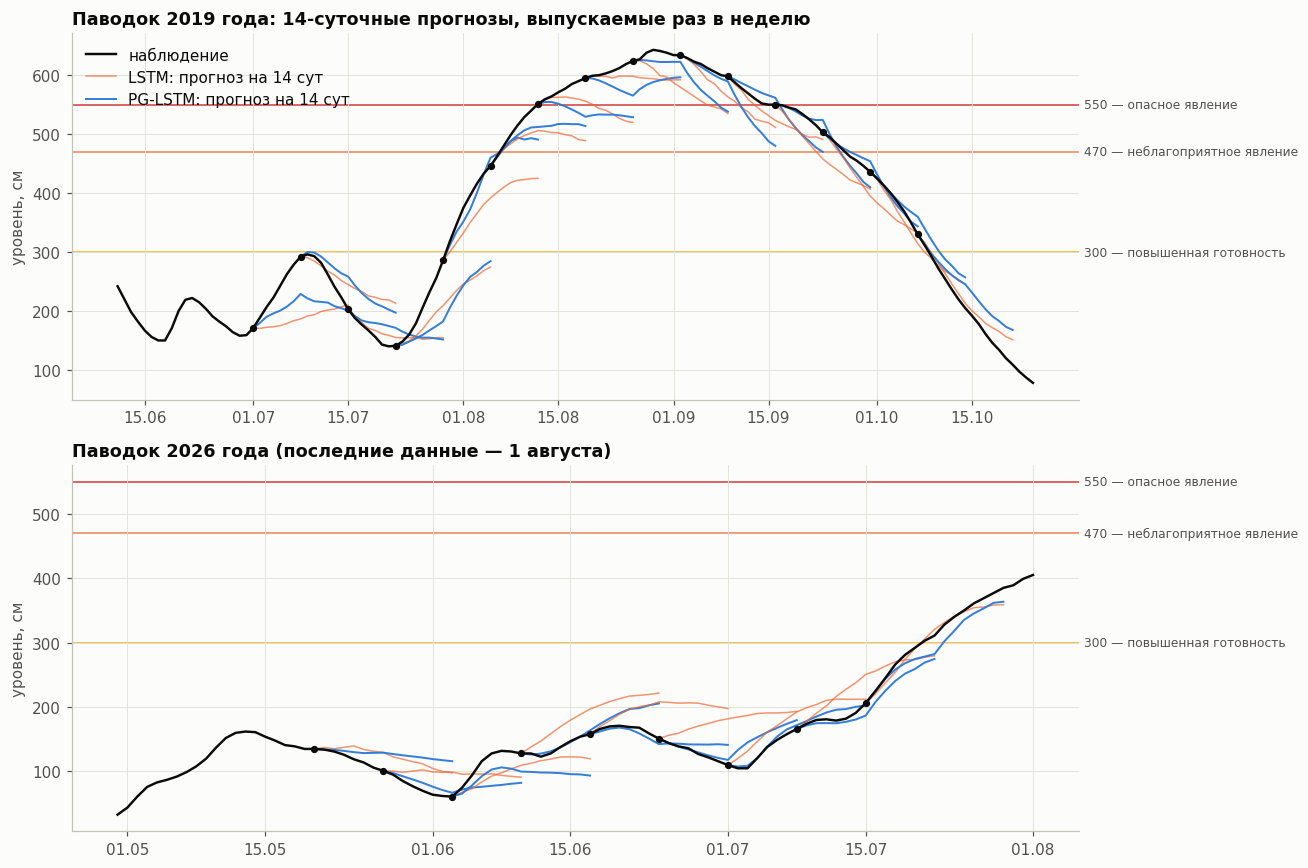

In [25]:
def fans(ax, start, end, step=7):
    w = (dates >= pd.Timestamp(start) - pd.Timedelta(days=20)) & (dates <= pd.Timestamp(end) + pd.Timedelta(days=14))
    ax.plot(dates[w], np.where(OBSv[w], Hv[w], np.nan), color=INK, lw=1.6, label='наблюдение', zorder=3)
    issue = [i for i, t in enumerate(te_idx) if pd.Timestamp(start) <= dates[t] <= pd.Timestamp(end)][::step]
    for j, i in enumerate(issue):
        t = te_idx[i]
        x = [dates[t]] + [dates[t] + pd.Timedelta(days=h) for h in range(1, HZ + 1)]
        for name in ['LSTM', 'PG-LSTM']:
            ax.plot(x, np.r_[Hv[t], Hv[t] + PRED[name][i]], color=COL[name], lw=1.3 if name == 'PG-LSTM' else 1,
                    alpha=0.95 if name == 'PG-LSTM' else 0.7, label=f'{name}: прогноз на 14 сут' if j == 0 else None)
        ax.scatter(dates[t], Hv[t], s=14, color=INK, zorder=4)
    thresholds(ax)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
    ax.set_ylabel('уровень, см')


fig, axes = plt.subplots(2, 1, figsize=(12, 8))
fans(axes[0], '2019-07-01', '2019-10-10')
axes[0].set_title('Паводок 2019 года: 14-суточные прогнозы, выпускаемые раз в неделю')
fans(axes[1], '2026-05-20', dates[te_idx[-1]].strftime('%Y-%m-%d'))
axes[1].set_title('Паводок 2026 года (последние данные — 1 августа)')
axes[0].legend(loc='upper left')
fig.tight_layout()
show(fig, '10_flood_fans.png')

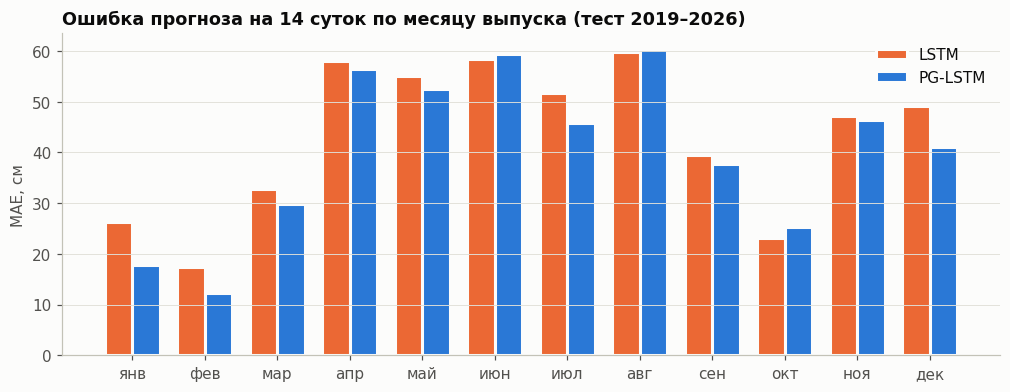

In [26]:
issue_month = dates[te_idx].month
by_month = pd.DataFrame({name: [np.abs(PRED[name][(issue_month == mo) & M_TE[:, 13], 13]
                                       - Y_TE[(issue_month == mo) & M_TE[:, 13], 13]).mean() for mo in range(1, 13)]
                         for name in ['LSTM', 'PG-LSTM']}, index=months)
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(12)
for k, name in enumerate(['LSTM', 'PG-LSTM']):
    ax.bar(x + (k - 0.5) * 0.38, by_month[name], width=0.38, color=COL[name], edgecolor=SURF, linewidth=2, label=name)
ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylabel('MAE, см')
ax.set_title('Ошибка прогноза на 14 суток по месяцу выпуска (тест 2019–2026)')
ax.grid(axis='x', visible=False)
ax.legend()
show(fig, '11_error_by_month.png')

### 6.2 Интервал прогноза

Для прогноза нужен и коридор. Квантили 10% и 90% ошибок PG-LSTM **на валидации** по каждому горизонту дают 80%-интервал. Проверяем на тесте, какая доля наблюдений в него попала (в идеале около 80%).

In [27]:
val_err = (VA[1].numpy() * SCALE - predict(models['PG-LSTM'], VA))
val_M = VA[2].numpy().astype(bool)
Q10 = np.array([np.quantile(val_err[val_M[:, h], h], 0.10) for h in range(HZ)])
Q90 = np.array([np.quantile(val_err[val_M[:, h], h], 0.90) for h in range(HZ)])
inside = (Y_TE >= PRED['PG-LSTM'] + Q10) & (Y_TE <= PRED['PG-LSTM'] + Q90)
cover = np.array([inside[M_TE[:, h], h].mean() * 100 for h in range(HZ)])
display(pd.DataFrame({'нижняя граница, см': Q10, 'верхняя граница, см': Q90, 'попадание на тесте, %': cover},
                     index=pd.Index(range(1, HZ + 1), name='h')).loc[show_h].round(1))

,"нижняя граница, см","верхняя граница, см","попадание на тесте, %"
h,,,
1,-4.200000,4.400000,75.7
3,-14.000000,14.000000,78.1
5,-25.200001,26.500000,79.4
7,-34.799999,34.799999,79.1
10,-39.000000,46.599998,75.0
14,-46.799999,60.599998,71.9


## 7. Сохранение модели и прогноз

В файл `model/pg_lstm_khabarovsk.pt` сохраняются:
* веса сетей ансамбля PG-LSTM;
* всё, что нужно для прогноза: признаки, масштабирование, архитектура, коэффициенты физической модели, интервалы;
* для отчёта: λ и метрики теста.

Затем модель загружается обратно функцией `pg_lstm.load_model` (так она будет работать в проекте) и строит прогноз от последней даты данных.

In [28]:
cfg = {
    'features': FEATURES, 'mean': f_mean.to_dict(), 'std': f_std.to_dict(),
    'arch': dict(ARCH, physics_input=True), 'routing': ROUTING_CFG,
    'window': WINDOW, 'horizon': HZ, 'scale': SCALE, 'lambda': LAM, 'mu': MU, 'seeds': list(SEEDS),
    'err_q10': Q10.tolist(), 'err_q90': Q90.tolist(), 'dmax_by_month': DMAX.to_dict(),
    'periods': {'train': f'{START.date()}…{TRAIN_END}', 'val': f'…{VAL_END}', 'test': f'…{END.date()}'},
    'test_metrics': MET['PG-LSTM'].round(3).to_dict(),
    'created': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
}
MODEL_PATH = MODEL_DIR / 'pg_lstm_khabarovsk.pt'
pg_lstm.save_model(MODEL_PATH, models['PG-LSTM'], cfg)
print(f'Сохранено: {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} КБ)')

model, cfg_loaded = pg_lstm.load_model(MODEL_PATH)              # как в проекте
check = pg_lstm.forecast(clean, model, cfg_loaded, date=dates[te_idx[-1]])
assert np.allclose(check['level'].values, Hv[te_idx[-1]] + PRED['PG-LSTM'][-1], atol=0.06), 'модель загрузилась не так'
print('Проверка загрузки: прогноз из файла совпадает с прогнозом в блокноте')

Сохранено: model/pg_lstm_khabarovsk.pt (1132 КБ)
Проверка загрузки: прогноз из файла совпадает с прогнозом в блокноте


Прогноз от 2026-08-01 (уровень в этот день 405 см):


date,2026-08-02,2026-08-03,2026-08-04,2026-08-05,2026-08-06,2026-08-07,2026-08-08,2026-08-09,2026-08-10,2026-08-11,2026-08-12,2026-08-13,2026-08-14,2026-08-15
horizon,1.000000,2.000000,3.000000,4.000000,5.0,6.000000,7.0,8.000000,9.000000,10.000000,11.000000,12.000000,13.0,14.000000
level,408.600006,411.899994,415.700012,421.700012,428.5,435.299988,443.0,464.299988,482.100006,498.399994,510.200012,517.099976,525.5,530.799988
level_low,404.400000,403.500000,401.700000,402.300000,403.3,405.300000,408.2,429.900000,446.400000,459.400000,469.700000,475.500000,481.9,484.000000
level_high,413.000000,420.600000,429.700000,441.100000,455.1,466.100000,477.8,502.100000,523.500000,545.000000,559.600000,569.100000,580.9,591.400000


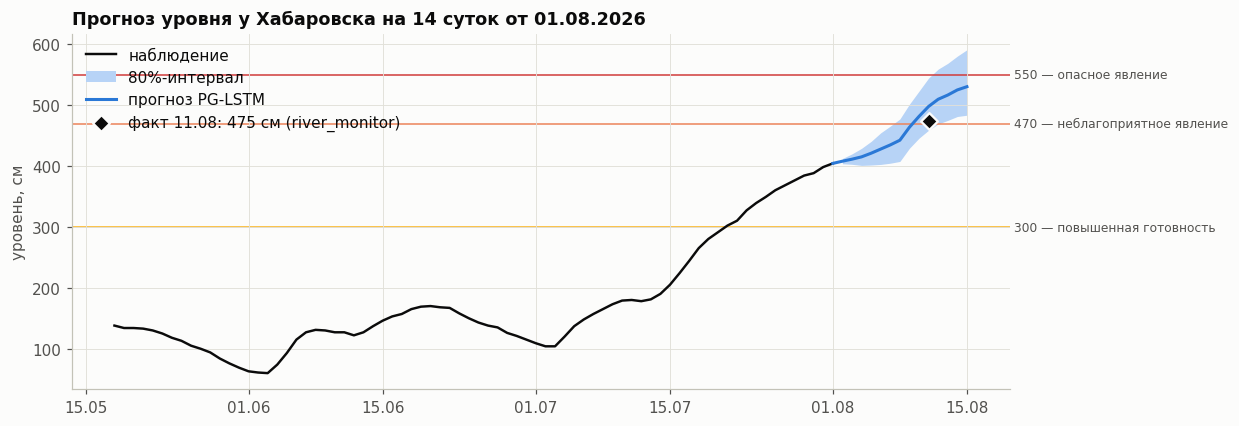

In [29]:
fc = pg_lstm.forecast(clean, model, cfg_loaded)                  # от последней даты в данных
LATER = {'2026-08-11': 475}   # фактический уровень из базы river_monitor (data/history.db), в обучении не участвовал
print(f'Прогноз от {END.date()} (уровень в этот день {Hv[-1]:.0f} см):')
display(fc.set_index('date').T)

fig, ax = plt.subplots(figsize=(11, 4.2))
w = dates >= END - pd.Timedelta(days=75)
ax.plot(dates[w], Hv[w], color=INK, lw=1.6, label='наблюдение')
ax.fill_between(fc['date'], fc['level_low'], fc['level_high'], color='#b7d3f6', lw=0, label='80%-интервал')
ax.plot(np.r_[[END], fc['date']], np.r_[Hv[-1], fc['level']], color=COL['PG-LSTM'], lw=2, label='прогноз PG-LSTM')
for d, v in LATER.items():
    ax.scatter(pd.Timestamp(d), v, s=60, color=INK, marker='D', edgecolor=SURF, linewidth=1.5, zorder=5,
               label=f'факт {pd.Timestamp(d):%d.%m}: {v} см (river_monitor)')
thresholds(ax)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
ax.set_ylabel('уровень, см')
ax.set_title(f'Прогноз уровня у Хабаровска на 14 суток от {END:%d.%m.%Y}')
ax.legend(loc='upper left')
show(fig, '12_forecast.png')

## 8. Подключение к проекту river_monitor

Подробно описано в `README.md`, коротко так:
1. Скопировать `pg_lstm.py` в `river_monitor/` и `model/pg_lstm_khabarovsk.pt` в `river_monitor/data/`. Добавить `torch` в `requirements.txt`.
2. В `forecast.py`:

```python
import pg_lstm

def get_pg_lstm_forecast():
    model, cfg = pg_lstm.load_model(DATA_DIR / 'pg_lstm_khabarovsk.pt')
    levels = {g: series_of(g) for g in pg_lstm.GAUGES}   # pd.Series уровней 4 постов, индекс — даты
    clean = pg_lstm.prepare_inputs(levels)               # очистка + ERA5 по бассейну + снег
    return pg_lstm.forecast(clean, model, cfg)           # date, horizon, level, level_low, level_high
```

Нужны уровни 4 постов минимум за последние 60 суток. Пропуски допустимы: модуль восстановит их и выставит флаги. Погоду ERA5 модуль скачает сам.

## 9. Выводы

1. **Данные.** Собран чистый датасет за 2002-01-01 — 2026-08-01 (8979 суток):
   * уровни Хабаровска и трёх постов выше по течению;
   * погода в Хабаровске (NASA POWER) и в 9 точках бассейна (ERA5);
   * снегозапас и водоотдача по модели градусо-дней.

   Удалено 37 ошибочных значений Хабаровска (коды 1050/1056, сбой датчика весной 2023, ошибки знака) и 8 на верхних постах. Пропуски восстановлены и помечены флагами. Файл: `data/amur_khabarovsk_clean.csv`.
2. **Физика реки.** Волна от Ленинского доходит до Хабаровска примерно за 2 суток, от Поярково за 7, от Благовещенска за 9. Уравнение маршрутизации (Маскингам / Калинин–Милюков) в приращениях уровня объясняет около 80% суточной изменчивости уровня на открытой воде (R² 0,79–0,85 на годах вне калибровки). Даже в одиночку оно хорошо прогнозирует на 1–5 суток.
3. **Модель.** PG-LSTM — это LSTM, которая поправляет физический прогноз и штрафуется за нарушение физики. На тесте 2019–2026:
   * MAE 4 см на 1 сутки, 24 см на 7 суток, 42 см на 14 суток;
   * на 14 сутках в 1,7 раза точнее инерционного прогноза;
   * на 5–34% точнее обычной LSTM (больше всего на ближних горизонтах).

   Ступени сравнения показывают вклад каждого пути физики. Физический прогноз на входе даёт основной выигрыш на 1–7 сутках. Штрафы добавляют ещё 1–2 см точности на 5–14 сутках и делают траекторию физически согласованной.
4. **Физическая согласованность.** Невязка уравнения маршрутизации у PG-LSTM 0,6 см/сут, у LSTM 3,3. Предел скорости PG-LSTM превышает реже: 0,17% прогнозов против 0,26%.
5. **Проверка на свежих данных.** Прогноз от 01.08.2026 на 11.08 — 498 см (коридор 459–545). Факт по базе river_monitor — 475 см: ошибка +23 см, внутри коридора.
6. **Ограничения и что улучшать.**
   * S/σΔ = 0,59–0,77, то есть «удовлетворительно». До «хорошо» (≤ 0,5) не хватает.
   * Наибольшие ошибки — в ледоход (апрель) и в летние паводки (июнь–август): заторные скачки не подчиняются уравнению маршрутизации, а летние подъёмы зависят от будущих дождей.
   * Информация с верхних постов заканчивается на 7–9 сутках. Дальше растёт неопределённость будущих осадков, а на стыке 7-х и 8-х суток траектория может иметь излом. Модель сознательно не использует прогноз погоды; добавление прогноза осадков Open-Meteo — следующий шаг.
   * 80%-коридор на тесте накрывает 72–79% наблюдений: тестовые годы многоводнее валидационных, коридор немного узковат.
   * Нет данных о сбросах Зейской и Бурейской ГЭС и о расходах Уссури. Их добавление должно заметно помочь.